# Figures, tables and numbers of the paper

*Algebraic Interaction Analysis for Concept-Based Explanations in Skin Cancer Diagnosis* (Nápoles and Grau)

This notebook rebuilds, from the simulation results alone, every figure and every table of the manuscript exactly as printed, and it recomputes every number quoted in the text.

* **Input.** The folder `AIA_SkinCon_results/` (the content of `AIA_SkinCon_results.zip`) next to this notebook, plus `assets/lesion1.png` for the schematic of Figure 1 and `assets/samples/` for the images of Figure 2. Nothing else is read, no model is evaluated and no image of the datasets is opened.
* **Output.** `output/` receives the seven figure PDFs with the file names used by the manuscript, PNG previews and the LaTeX bodies of Tables 1 to 3.
* **Checks.** The tables are compared character for character with the manuscript. Every number of the text is recomputed and compared with the printed value, and a failed check stops the notebook. When `reference_figures/` holds the PDFs of the manuscript, the last cell compares the rebuilt figures with them pixel by pixel.

Run all cells from top to bottom. A full run takes about one minute on a laptop.

| File | Figure in the manuscript |
|---|---|
| `fig0_pipeline.pdf` | Figure 1 |
| `fig1_samples.pdf` | Figure 2 |
| `fig2_computation.pdf` | Figure 3 |
| `fig3_parity.pdf` | Figure 4 |
| `fig4_decisions.pdf` | Figure 5 |
| `fig6_summaries.pdf` | Figure 6 |
| `fig5_pairs.pdf` | Figure 7 |


In [1]:
import os, sys, platform
import matplotlib
matplotlib.use("Agg")
import numpy as np, pandas as pd, scipy, seaborn
from IPython.display import Image, display

RESULTS = "AIA_SkinCon_results"           # unzipped AIA_SkinCon_results.zip
OUTPUT_DIR = "output"
PREVIEW_DIR = os.path.join(OUTPUT_DIR, "previews")
os.makedirs(PREVIEW_DIR, exist_ok=True)
for need in ("tuned/csv/e2_controls.csv", "baseline/csv/e2_controls.csv", "image_level/tuned_images.csv",
             "image_level/e1_expected_hard_images.csv", "data/part1_data_summary.txt"):
    assert os.path.exists(os.path.join(RESULTS, need)), f"missing {need}: unzip AIA_SkinCon_results.zip next to this notebook"
assert os.path.exists("assets/lesion1.png"), "missing assets/lesion1.png"
assert len([f for f in os.listdir("assets/samples") if f.endswith(".jpg")]) == 9, "missing assets/samples"
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", seaborn.__version__)
print("The figures of the manuscript were produced with numpy 2.4.4, pandas 3.0.2, scipy 1.17.1, matplotlib 3.10.9 and seaborn 0.13.2.")

Python 3.11.15 | numpy 2.4.4 | pandas 3.0.2 | scipy 1.17.1 | matplotlib 3.10.9 | seaborn 0.13.2
The figures of the manuscript were produced with numpy 2.4.4, pandas 3.0.2, scipy 1.17.1, matplotlib 3.10.9 and seaborn 0.13.2.


## Figure 1. Schematic of the analysis

Fictional concepts, games and values, as stated in the caption. The lesion thumbnail is `assets/lesion1.png`.

saved output/fig0_pipeline.pdf


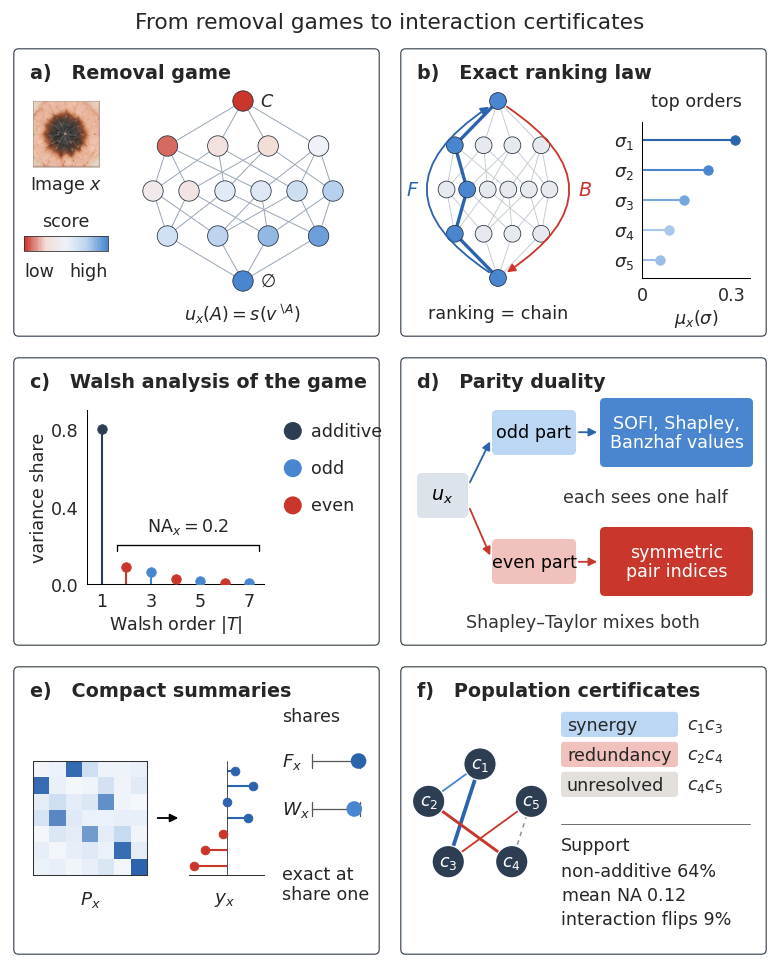

In [2]:
"""Schematic of algebraic interaction analysis (Figure 1 of the article).
Same canvas width, font size and color palette as the result figures."""
import itertools, os
import matplotlib as _mpl
_mpl.rcdefaults()
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle, Circle, Polygon
from matplotlib.colors import LinearSegmentedColormap
from scipy.spatial import ConvexHull

OUT = OUTPUT_DIR + "/"
LESIONS = "assets/"
FS = 21
# A 13 in canvas with FS = 21 prints figure text at the size of the captions once scaled to the text width.
WIDTH = 13.0
GREY = "grey"
sns.set_theme(style="whitegrid", rc={
    "font.size": FS, "axes.titlesize": FS, "axes.labelsize": FS, "xtick.labelsize": FS, "ytick.labelsize": FS,
    "legend.fontsize": FS, "legend.title_fontsize": FS, "figure.titlesize": FS, "font.family": "DejaVu Sans",
    "axes.edgecolor": GREY, "grid.color": "#dddddd", "axes.titleweight": "bold", "legend.frameon": False,
    "pdf.fonttype": 42})

# ---------------- palette of the schematic ----------------
SC_BLUE_D, SC_BLUE, SC_BLUE_L, SC_RED, SC_RED_L, SC_GREYV, SC_NAVY = "#2c63ad", "#4a86cf", "#a9c7ea", "#c9362c", "#eab3a8", "#8c9199", "#2d3e52"
SC_CMAP = LinearSegmentedColormap.from_list("bw", [SC_RED, "#f3dcd6", "#eef2f8", "#bcd3ee", SC_BLUE])
MINUS = "−"

# ---------------- permutohedron of order 4 (truncated octahedron) ----------------
P4 = np.array(list(itertools.permutations([1, 2, 3, 4])), float)
P4 -= P4.mean(1, keepdims=True)
Bs = np.linalg.qr(np.vstack([np.ones(4), np.eye(4)[:3]]).T)[0][:, 1:4]
V = P4 @ Bs
V /= np.abs(V).max()
hull = ConvexHull(V)
faces = []
for eq in np.unique(np.round(hull.equations, 6), axis=0):
    idx = np.where(np.abs(V @ eq[:3] + eq[3]) < 1e-6)[0]
    c = V[idx].mean(0); nrm = eq[:3]
    u = V[idx[0]] - c; u /= np.linalg.norm(u); w = np.cross(nrm, u)
    ang = np.arctan2((V[idx] - c) @ w, (V[idx] - c) @ u)
    faces.append((idx[np.argsort(ang)], nrm))
edges = {tuple(sorted((a, b))) for a, b in itertools.combinations(range(24), 2)
         if np.sum(P4[a] != P4[b]) == 2 and abs(np.abs(P4[a] - P4[b]).max() - 1) < 1e-9}


def rot(ax_, ay_, az_=0.0):
    cx, sx, cy, sy, cz, sz = np.cos(ax_), np.sin(ax_), np.cos(ay_), np.sin(ay_), np.cos(az_), np.sin(az_)
    Rx = np.array([[1, 0, 0], [0, cx, -sx], [0, sx, cx]])
    Ry = np.array([[cy, 0, sy], [0, 1, 0], [-sy, 0, cy]])
    Rz = np.array([[cz, -sz, 0], [sz, cz, 0], [0, 0, 1]])
    return Rz @ Rx @ Ry


def draw_poly(ax, cx, cy, s, R, face_color, vert_color, lw=1.6, vsize=1.0, alpha=0.78):
    X = V @ R.T
    xy = np.c_[cx + s * X[:, 0], cy + s * X[:, 1]]
    order = sorted(range(len(faces)), key=lambda i: (R @ faces[i][1])[2])
    for i in order:
        idx, n_ = faces[i]
        front = (R @ n_)[2] > 0
        ax.add_patch(Polygon(xy[idx], closed=True, facecolor=face_color(i, X[idx][:, 1].mean()), edgecolor="none",
                             alpha=alpha if front else 0.35, zorder=2 if front else 1))
    for a, b in edges:
        front = any((R @ faces[i][1])[2] > 0 for i in range(len(faces)) if a in faces[i][0] and b in faces[i][0])
        ax.plot(xy[[a, b], 0], xy[[a, b], 1], color=SC_NAVY if front else "#9aa7b8", lw=lw if front else lw * 0.6,
                alpha=0.85 if front else 0.5, zorder=3 if front else 1.5, solid_capstyle="round")
    for k in range(24):
        if X[k, 2] < -0.25:
            continue
        ax.add_patch(Circle(xy[k], 0.06 * s * vsize, facecolor=vert_color(k, X[k, 1]), edgecolor="#1e2a38", lw=0.8, zorder=4))
    return xy, X


def vcol(k, y):
    if y > 0.45:
        return SC_BLUE
    if y < -0.45:
        return SC_RED
    return [SC_GREYV, SC_NAVY, SC_RED, SC_BLUE][k % 4]


# ---------------- Boolean lattice of four concepts ----------------
NL = 4
SUBSETS = [S for k in range(NL + 1) for S in itertools.combinations(range(NL), k)]


def lattice_xy(x0, x1, y0, y1):
    pos = {}
    for k in range(NL + 1):
        layer = [S for S in SUBSETS if len(S) == k]
        xs = np.linspace(x0, x1, len(layer) + 2)[1:-1] if len(layer) > 1 else [(x0 + x1) / 2]
        for S, x in zip(layer, xs):
            pos[S] = (x, y0 + k * (y1 - y0) / NL)
    return pos


def lattice_edges():
    return [(S, T) for S in SUBSETS for T in SUBSETS if len(T) == len(S) + 1 and set(S) <= set(T)]


# fictional game: removing concepts lowers the melanoma score, with one interacting pair
EFF = np.array([1.1, 0.8, 0.5, 0.25])
def game(S):
    v = 1.6 - EFF[list(S)].sum()
    if 0 in S and 2 in S:
        v -= 0.45
    return v
GV = {S: game(S) for S in SUBSETS}
GMIN, GMAX = min(GV.values()), max(GV.values())


def gcol(S):
    return SC_CMAP((GV[S] - GMIN) / (GMAX - GMIN))


# ---------------- canvas with the panel grid of the schematic ----------------
W_, H_ = WIDTH, 16.15
fig = plt.figure(figsize=(W_, H_))
M, G, T, PH = 0.2, 0.3, 0.8, 4.85
PW = (W_ - 2 * M - G) / 2
fig.text(0.5, 1 - 0.38 / H_, "From removal games to interaction certificates", ha="center", va="center", fontsize=FS + 5)


def panel(r, c, title):
    x0 = M + c * (PW + G); y0 = H_ - T - (r + 1) * PH - r * G
    ax = fig.add_axes([x0 / W_, y0 / H_, PW / W_, PH / H_])
    ax.set_xlim(0, PW); ax.set_ylim(0, PH); ax.axis("off")
    ax.add_patch(FancyBboxPatch((0.03, 0.03), PW - 0.06, PH - 0.06, boxstyle="round,pad=0,rounding_size=0.08",
                                facecolor="white", edgecolor="#3b4450", lw=1.4, zorder=0))
    ax.text(0.3, PH - 0.42, title, fontsize=FS + 2, fontweight="bold", va="center", ha="left")
    return ax, x0, y0


def box(ax, x, y, w, h, fc, text=None, color="black", fs=FS):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=0.08", facecolor=fc, edgecolor="none", zorder=3))
    if text:
        ax.text(x + w / 2, y + h / 2, text, fontsize=fs, ha="center", va="center", color=color, zorder=4, linespacing=1.1)


def arrow(ax, a, b, col="black", lw=2.2, rad=0.0, ms=20, ls="-"):
    ax.add_patch(FancyArrowPatch(a, b, connectionstyle=f"arc3,rad={rad}", arrowstyle="-|>", color=col, lw=lw,
                                 mutation_scale=ms, zorder=5, linestyle=ls))


def spines(ia):
    ia.grid(False)
    for sp in ["top", "right"]:
        ia.spines[sp].set_visible(False)
    ia.spines["left"].set_color("black"); ia.spines["bottom"].set_color("black")


# ---------------- a) removal game on the subset lattice ----------------
ax, _, _ = panel(0, 0, "a)   Removal game")
img = plt.imread(LESIONS + "lesion1.png")
ax.imshow(img, extent=(0.35, 1.45, 2.85, 3.95), zorder=3)
ax.add_patch(Rectangle((0.35, 2.85), 1.1, 1.1, fill=False, edgecolor="#b8a79c", lw=0.8, zorder=4))
ax.text(0.9, 2.55, "Image $x$", fontsize=FS, ha="center", va="center")
ax.text(0.9, 1.95, "score", fontsize=FS, ha="center", va="center")
for k in range(60):
    ax.add_patch(Rectangle((0.2 + k * 1.4 / 60, 1.45), 1.4 / 60 + 0.004, 0.25, facecolor=SC_CMAP(k / 59), edgecolor="none"))
ax.add_patch(Rectangle((0.2, 1.45), 1.4, 0.25, fill=False, edgecolor="#333", lw=1))
ax.text(0.2, 1.12, "low", fontsize=FS, ha="left", va="center")
ax.text(1.6, 1.12, "high", fontsize=FS, ha="right", va="center")
pos = lattice_xy(1.75, 5.95, 0.95, 3.95)
for S, Tt in lattice_edges():
    ax.plot(*zip(pos[S], pos[Tt]), color="#9aa7b8", lw=1.2, zorder=1)
for S in SUBSETS:
    ax.add_patch(Circle(pos[S], 0.17, facecolor=gcol(S), edgecolor="#1e2a38", lw=0.9, zorder=3))
ax.text(pos[()][0] + 0.28, pos[()][1], r"$\varnothing$", fontsize=FS, va="center")
ax.text(pos[(0, 1, 2, 3)][0] + 0.28, pos[(0, 1, 2, 3)][1], "$C$", fontsize=FS, va="center")
ax.text(3.85, 0.42, r"$u_x(A)=s(v^{\setminus A})$", fontsize=FS, ha="center", va="center")

# ---------------- b) exact Gibbs-SOFI law ----------------
ax, x0, y0 = panel(0, 1, "b)   Exact ranking law")
pos = lattice_xy(0.45, 2.85, 1.0, 3.95)
chain = [(), (0,), (0, 2), (0, 1, 2), (0, 1, 2, 3)]
for S, Tt in lattice_edges():
    on = S in chain and Tt in chain and chain.index(Tt) == chain.index(S) + 1
    ax.plot(*zip(pos[S], pos[Tt]), color=SC_BLUE_D if on else "#c3cad4", lw=4 if on else 1.1, zorder=2 if on else 1)
NODE = {}
for S in SUBSETS:
    on = S in chain
    NODE[S] = Circle(pos[S], 0.14, facecolor=SC_BLUE if on else "#e6e9ee", edgecolor="#1e2a38", lw=0.9, zorder=3)
    ax.add_patch(NODE[S])
TOP = (0, 1, 2, 3)
# forward weights accumulate from the empty set upward, backward weights from C downward; both arrows leave the
# border of one node and end on the border of the other
ax.add_patch(FancyArrowPatch(posA=pos[()], posB=pos[TOP], patchA=NODE[()], patchB=NODE[TOP],
                             connectionstyle="arc3,rad=-0.8", arrowstyle="-|>", color=SC_BLUE_D, lw=2.2,
                             mutation_scale=20, zorder=5, shrinkA=2, shrinkB=2))
ax.text(0.22, 2.48, "$F$", fontsize=FS + 2, color=SC_BLUE_D, ha="center", va="center")
ax.add_patch(FancyArrowPatch(posA=pos[TOP], posB=pos[()], patchA=NODE[TOP], patchB=NODE[()],
                             connectionstyle="arc3,rad=-0.8", arrowstyle="-|>", color=SC_RED, lw=2.2,
                             mutation_scale=20, zorder=5, shrinkA=2, shrinkB=2))
ax.text(3.1, 2.48, "$B$", fontsize=FS + 2, color=SC_RED, ha="center", va="center")
ax.text(1.65, 0.42, "ranking = chain", fontsize=FS, ha="center", va="center")
ia = fig.add_axes([(x0 + 4.05) / W_, (y0 + 1.0) / H_, 1.8 / W_, 2.6 / H_])
probs = np.array([0.31, 0.22, 0.14, 0.09, 0.06])
for k_, (p_, c_) in enumerate(zip(probs, [SC_BLUE_D, SC_BLUE, "#76a6de", SC_BLUE_L, "#9dbde6"])):
    ia.plot([0, p_], [k_, k_], color=c_, lw=2.5, solid_capstyle="butt")
    ia.scatter([p_], [k_], s=130, color=c_, zorder=3)
ia.set_ylim(4.6, -0.6)
ia.set_yticks(range(5), [rf"$\sigma_{k + 1}$" for k in range(5)]); ia.set_xlim(0, 0.36); ia.set_xticks([0, 0.3], ["0", "0.3"])
spines(ia)
ia.set_xlabel(r"$\mu_x(\sigma)$")
ax.text(4.95, 3.95, "top orders", fontsize=FS, ha="center", va="center")

# ---------------- c) Walsh spectrum with the additivity certificate ----------------
ax, x0, y0 = panel(1, 0, "c)   Walsh analysis of the game")
ia = fig.add_axes([(x0 + 1.25) / W_, (y0 + 1.05) / H_, 2.95 / W_, 2.9 / H_])
orders = np.arange(1, 8)
energy = np.array([0.80, 0.09, 0.06, 0.025, 0.015, 0.006, 0.004])
cols = [SC_NAVY] + [SC_RED if k % 2 == 0 else SC_BLUE for k in orders[1:]]
for o_, e_, c_ in zip(orders, energy, cols):
    ia.plot([o_, o_], [0, e_], color=c_, lw=2.5, solid_capstyle="butt")
    ia.scatter([o_], [e_], s=130, color=c_, zorder=3)
ia.set_xlim(0.4, 7.6)
ia.set_xticks([1, 3, 5, 7]); ia.set_yticks([0, 0.4, 0.8], ["0.0", "0.4", "0.8"])
ia.set_ylim(0, 0.9)
spines(ia)
ia.set_xlabel("Walsh order $|T|$"); ia.set_ylabel("variance share")
ia.plot([1.6, 7.4], [0.2, 0.2], color="black", lw=1.6)
for xx in (1.6, 7.4):
    ia.plot([xx, xx], [0.17, 0.2], color="black", lw=1.6)
ia.text(4.5, 0.25, r"$\mathrm{NA}_x=0.2$", fontsize=FS, ha="center", va="bottom")
lx = 4.5
for k, (col, lab) in enumerate([(SC_NAVY, "additive"), (SC_BLUE, "odd"), (SC_RED, "even")]):
    yy = 3.6 - 0.62 * k
    ax.add_patch(Circle((lx + 0.18, yy), 0.15, facecolor=col, edgecolor="none"))
    ax.text(lx + 0.48, yy, lab, fontsize=FS, va="center")

# ---------------- d) parity duality ----------------
ax, _, _ = panel(1, 1, "d)   Parity duality")
box(ax, 0.3, 2.15, 0.85, 0.75, "#dde3ea", "$u_x$", fs=FS + 2)
box(ax, 1.55, 3.2, 1.4, 0.75, "#bcd7f3", "odd part")
box(ax, 1.55, 1.05, 1.4, 0.75, "#f1c1bd", "even part")
arrow(ax, (1.17, 2.72), (1.53, 3.45), SC_BLUE_D)
arrow(ax, (1.17, 2.33), (1.53, 1.5), SC_RED)
box(ax, 3.35, 3.0, 2.55, 1.15, SC_BLUE, "SOFI, Shapley,\nBanzhaf values", color="white")
box(ax, 3.35, 0.85, 2.55, 1.15, SC_RED, "symmetric\npair indices", color="white")
arrow(ax, (2.97, 3.58), (3.33, 3.58), SC_BLUE_D)
arrow(ax, (2.97, 1.42), (3.33, 1.42), SC_RED)
ax.text(4.1, 2.5, "each sees one half", fontsize=FS, ha="center", va="center", color="#333")
ax.text(3.07, 0.42, "Shapley\u2013Taylor mixes both", fontsize=FS, ha="center", va="center", color="#333")

# ---------------- e) compact summaries ----------------
ax, x0, y0 = panel(2, 0, "e)   Compact summaries")
rng = np.random.default_rng(3)
Pm = np.eye(7)[[2, 0, 4, 1, 3, 5, 6]] * 0.55 + rng.dirichlet(np.ones(7), 7) * 0.45
for _ in range(20):
    Pm = Pm / Pm.sum(0, keepdims=True); Pm = Pm / Pm.sum(1, keepdims=True)
ih = fig.add_axes([(x0 + 0.35) / W_, (y0 + 1.35) / H_, 1.9 / W_, 1.9 / H_])
ih.imshow(Pm, cmap=LinearSegmentedColormap.from_list("b", ["#f4f7fb", SC_BLUE_L, SC_BLUE_D]), vmin=0, vmax=0.7)
ih.set_xticks([]); ih.set_yticks([]); ih.grid(False)
for sp in ih.spines.values():
    sp.set_color("#333")
ax.text(1.3, 0.95, "$P_x$", fontsize=FS + 1, ha="center", va="center")
arrow(ax, (2.4, 2.3), (2.8, 2.3))
yv = Pm @ (4.0 - np.arange(1, 8))
iy = fig.add_axes([(x0 + 2.95) / W_, (y0 + 1.35) / H_, 1.25 / W_, 1.9 / H_])
for k_, v_ in enumerate(yv):
    c_ = SC_BLUE_D if v_ > 0 else SC_RED
    iy.plot([0, v_], [k_, k_], color=c_, lw=2.5, solid_capstyle="butt")
    iy.scatter([v_], [k_], s=110, color=c_, zorder=3)
iy.set_ylim(6.6, -0.6); iy.set_xlim(-1.15 * np.abs(yv).max(), 1.15 * np.abs(yv).max())
iy.axvline(0, color="#333", lw=1)
iy.set_yticks([]); iy.set_xticks([]); iy.grid(False)
for sp in ["top", "right", "left"]:
    iy.spines[sp].set_visible(False)
iy.spines["bottom"].set_color("#333")
ax.text(3.55, 0.95, "$y_x$", fontsize=FS + 1, ha="center", va="center")
bx = 4.5
ax.text(bx, 4.0, "shares", fontsize=FS, va="center")
for k, (lab, val, col) in enumerate([("$F_x$", 0.97, SC_BLUE_D), ("$W_x$", 0.88, SC_BLUE)]):
    yy = 3.25 - 0.8 * k
    ax.plot([bx + 0.5, bx + 1.3], [yy, yy], color="#555", lw=1.5)
    for xe in (bx + 0.5, bx + 1.3):
        ax.plot([xe, xe], [yy - 0.12, yy + 0.12], color="#555", lw=1.5)
    ax.add_patch(Circle((bx + 0.5 + 0.8 * val, yy), 0.13, facecolor=col, edgecolor="none", zorder=4))
    ax.text(bx, yy, lab, fontsize=FS + 1, va="center")
ax.text(bx, 1.2, "exact at\nshare one", fontsize=FS, va="center", linespacing=1.1)

# ---------------- f) population certificates ----------------
ax, _, _ = panel(2, 1, "f)   Population certificates")
ang = np.deg2rad(90 + np.arange(5) * 72)
nodes = {f"c_{k + 1}": (1.35 + 0.9 * np.cos(a), 2.3 + 0.9 * np.sin(a)) for k, a in enumerate(ang)}
links = [("c_1", "c_3", SC_BLUE_D, 4.5, "-"), ("c_2", "c_4", SC_RED, 3.5, "-"), ("c_1", "c_2", SC_BLUE, 2.2, "-"),
         ("c_3", "c_5", SC_RED, 2.2, "-"), ("c_4", "c_5", SC_GREYV, 1.8, (0, (3, 3)))]
for a, b, col, lw, ls in links:
    ax.plot(*zip(nodes[a], nodes[b]), color=col, lw=lw, ls=ls, zorder=2)
for lb, (x, y) in nodes.items():
    ax.add_patch(Circle((x, y), 0.27, facecolor=SC_NAVY, edgecolor="white", lw=1.5, zorder=3))
    ax.text(x, y, f"${lb}$", fontsize=FS, ha="center", va="center", color="white", zorder=4)
for k, (lb, cc, pr) in enumerate([("synergy", "#bcd7f3", "$c_1c_3$"), ("redundancy", "#f1c1bd", "$c_2c_4$"),
                                  ("unresolved", "#e3dfdb", "$c_4c_5$")]):
    yy = 3.85 - 0.5 * k
    ax.add_patch(FancyBboxPatch((2.7, yy - 0.2), 1.95, 0.42, boxstyle="round,pad=0,rounding_size=0.06", facecolor=cc, edgecolor="none"))
    ax.text(2.8, yy, lb, fontsize=FS, va="center")
    ax.text(4.8, yy, pr, fontsize=FS, va="center")
ax.plot([2.7, 5.85], [2.2, 2.2], color="#555", lw=1)
ax.text(2.7, 1.85, "Support", fontsize=FS, va="center")
for k, t in enumerate(["non-additive 64%", r"mean $\mathrm{NA}$ 0.12", "interaction flips 9%"]):
    ax.text(2.7, 1.42 - 0.4 * k, t, fontsize=FS, va="center")

fig.savefig(OUT + "fig0_pipeline.pdf")
fig.savefig(PREVIEW_DIR + "/fig0_pipeline.png", dpi=60)
plt.close(fig)
print("saved", OUT + "fig0_pipeline.pdf")

display(Image(PREVIEW_DIR + "/fig0_pipeline.png"))

## Figure 2. Images of the study

Nine Fitzpatrick17k images from `assets/samples/`, with their diagnosis from the Fitzpatrick17k metadata (`assets/samples/fitzpatrick17k.csv`, the nine rows of these images). Every image is cropped around its center to a 4 by 3 aspect ratio and resized to the same size.

saved output/fig1_samples.pdf


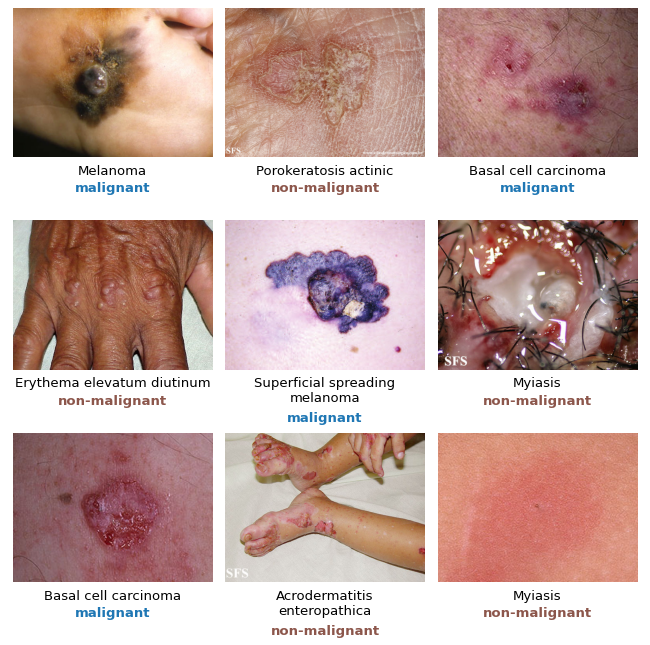

In [3]:
"""Figure of nine Fitzpatrick17k images used in the study, with their diagnosis from the Fitzpatrick17k metadata.
Every image is cropped around its center to the same horizontal aspect ratio (4:3) and resized to the same size."""
import os, textwrap
import numpy as np
import pandas as pd
import matplotlib
matplotlib.rcdefaults()
import matplotlib.pyplot as plt
from PIL import Image as PILImage

SAMPLES = "assets/samples"
OUT = OUTPUT_DIR + "/"
FS = 21
BLUE, BROWN = "tab:blue", "tab:brown"           # malignant and non-malignant, as in the result figures
ORDER = ["cb0bd4370fb0154d4d13e6495ef746d8", "c51c8a600fe6106f11259769cd416b08", "dbb854f5cf3cc3ebf4912e860da2efc7",
         "d580ec558ddf9a24e4895f1fcde261bd", "dc6b70e34949c1fa255c0c936fc53655", "d7c4be13319c37084dabfcec66c3b4f8",
         "e3e180ecaeadef19fd487caab7655316", "dd475371465408a8cbe2ccec9587e6a3", "c45a75c3484017b978a3794ec3b93394"]
ASPECT, SIZE = 4 / 3, (400, 300)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": FS, "pdf.fonttype": 42})
meta = pd.read_csv(os.path.join(SAMPLES, "fitzpatrick17k.csv")).set_index("md5hash")


def crop_resize(path):
    im = PILImage.open(path).convert("RGB")
    w, h = im.size
    if w / h > ASPECT:                                  # too wide: trim the sides
        nw = int(round(h * ASPECT))
        im = im.crop(((w - nw) // 2, 0, (w - nw) // 2 + nw, h))
    else:                                               # too tall: trim top and bottom
        nh = int(round(w / ASPECT))
        im = im.crop((0, (h - nh) // 2, w, (h - nh) // 2 + nh))
    return np.asarray(im.resize(SIZE, PILImage.LANCZOS))


W, PW, PH, GAPX, LAB, TOP = 13.0, 4.0, 3.0, 0.25, 1.25, 0.15
H = TOP + 3 * (PH + LAB)
fig = plt.figure(figsize=(W, H))
x0 = (W - 3 * PW - 2 * GAPX) / 2
for k, md5 in enumerate(ORDER):
    r, c = divmod(k, 3)
    ax = fig.add_axes([(x0 + c * (PW + GAPX)) / W, (H - TOP - (r + 1) * PH - r * LAB) / H, PW / W, PH / H])
    ax.imshow(crop_resize(os.path.join(SAMPLES, md5 + ".jpg")))
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    row = meta.loc[md5]
    malignant = row.three_partition_label == "malignant"
    name = row.label[0].upper() + row.label[1:]
    name = name.replace(" ssm", "")
    ax.text(0.5, -0.05, "\n".join(textwrap.wrap(name, 26)), transform=ax.transAxes, ha="center", va="top", fontsize=FS - 2)
    ax.text(0.5, -0.05 - 0.115 * (len(textwrap.wrap(name, 26))), "malignant" if malignant else "non-malignant",
            transform=ax.transAxes, ha="center", va="top", fontsize=FS - 2, color=BLUE if malignant else BROWN,
            fontweight="bold")
fig.savefig(OUT + "fig1_samples.pdf", dpi=100)
fig.savefig(PREVIEW_DIR + "/fig1_samples.png", dpi=50)
print("saved", OUT + "fig1_samples.pdf")

display(Image(PREVIEW_DIR + "/fig1_samples.png"))

## Figures 3 to 7. Results on SkinCon

Shared style and helpers. Blue marks malignant and brown non-malignant images. The cells below must run in this order, since Figure 5c draws bootstrap samples from one random generator seeded here.

In [4]:
"""Result figures of the article on SkinCon (real data only).
Rules: blue (malignant) and brown (non-malignant) are the only colors of data marks, black is used for lines only,
grey for shaded areas only, no bars, boxplots only for large samples and without point clouds. Every panel has the
same size (4.7 in by 3.4 in) on a 13 in canvas, so the printed font size is identical across figures."""
import os
import numpy as np
import matplotlib as _mpl
_mpl.rcdefaults()
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import NullFormatter, FixedLocator
from scipy.stats import spearmanr

A = RESULTS + "/tuned/csv/"                # tuned models (primary family)
B = RESULTS + "/baseline/csv/"             # baseline models (replication family)
IMAGE_LEVEL = RESULTS + "/image_level/"
OUT = OUTPUT_DIR + "/"
PNG = PREVIEW_DIR + "/"
os.makedirs(PNG, exist_ok=True)
FS = 21
CANVAS_W = 13.0
PW, PH = 4.7, 3.4                          # panel size in inches, identical in every figure
COLX = (1.45, 8.05)                        # left edges of the two panel columns
BLUE, BROWN, BLACK = "tab:blue", "tab:brown", "black"
SHADE = "#ececec"
POPS = ("malignant", "non_malignant")
PCOL = {"malignant": BLUE, "non_malignant": BROWN}
OFF = {"malignant": -0.12, "non_malignant": 0.12}
sns.set_theme(style="whitegrid", rc={
    "font.size": FS, "axes.titlesize": FS, "axes.labelsize": FS, "xtick.labelsize": FS, "ytick.labelsize": FS,
    "legend.fontsize": FS, "legend.title_fontsize": FS, "font.family": "DejaVu Sans", "axes.edgecolor": "grey",
    "grid.color": "#dddddd", "axes.titleweight": "bold", "axes.titlepad": 12, "legend.frameon": False,
    "pdf.fonttype": 42})
RNG = np.random.default_rng(5)
MS = 10          # marker size of summary markers (points)
SC = 70          # scatter marker area for image-level clouds


def csv(path, name):
    return pd.read_csv(path + name + ".csv", keep_default_na=False, na_values=[""])


def canvas(rows, top_extra=0.0, legend_rows=2):
    """Figure with rows x 2 panels of identical size at fixed positions (inches)."""
    top, gap, bottom = 0.65, 1.85, 1.2
    legend_h = LEGEND_PAD + legend_rows * LEGEND_ROW      # the legend area grows with its rows only
    H = top + top_extra + rows * PH + (rows - 1) * gap + bottom + legend_h
    fig = plt.figure(figsize=(CANVAS_W, H))
    axes = []
    for r in range(rows):
        y = H - top - top_extra - (r + 1) * PH - r * gap
        axes.append([fig.add_axes([x / CANVAS_W, y / H, PW / CANVAS_W, PH / H]) for x in COLX])
    return fig, np.array(axes), H


LEGEND_ROW, LEGEND_PAD = 0.42, 0.2                 # inches per legend row and below the legend


def legend_below(fig, H, handles, labels, ncol):
    """Legend at a fixed distance below the x labels of the lowest panels, identical in every figure."""
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, LEGEND_PAD / H), ncol=ncol, frameon=False,
               handletextpad=0.6, columnspacing=1.6, handler_map={tuple: HandlerTuple(ndivide=None, pad=0.4)})


def both(**kw):
    """Legend handle shown in both population colors, for a style that applies to both populations."""
    out = []
    for c in (BLUE, BROWN):
        k = dict(kw)
        if k.get("mfc") == "COLOR":
            k["mfc"] = c
        out.append(Line2D([], [], color=c, **k))
    return tuple(out)


def save(fig, name):
    fig.savefig(OUT + name + ".pdf")
    fig.savefig(PNG + name + ".png", dpi=55)
    plt.close(fig)
    print("saved", name)


def dot(ax, x, y, color, filled=True, ms=MS, marker="o", zorder=4):
    ax.plot(x, y, marker=marker, ls="", ms=ms, color=color, mfc=color if filled else "white", mec=color, mew=2,
            zorder=zorder)


def iqr_dot(ax, x, values, color, filled=True, vert=True, ms=MS, marker="o"):
    """Median with its interquartile range."""
    v = np.asarray(values, float)
    v = v[np.isfinite(v)]
    q1, med, q3 = np.percentile(v, [25, 50, 75])
    if vert:
        ax.plot([x, x], [q1, q3], color=color, lw=2.2, zorder=3)
        dot(ax, x, med, color, filled, ms, marker)
    else:
        ax.plot([q1, q3], [x, x], color=color, lw=2.2, zorder=3)
        dot(ax, med, x, color, filled, ms, marker)
    return med


def box(ax, values, pos, color, width=0.32):
    v = np.asarray(values, float)
    v = v[np.isfinite(v)]
    ax.boxplot(v, positions=[pos], widths=width, patch_artist=True, showfliers=False, manage_ticks=False,
               boxprops=dict(facecolor="white", edgecolor=color, lw=2.2), medianprops=dict(color=color, lw=3),
               whiskerprops=dict(color=color, lw=2), capprops=dict(color=color, lw=2), zorder=2)


def no_minor(ax, axis="y"):
    (ax.yaxis if axis == "y" else ax.xaxis).set_minor_formatter(NullFormatter())


POP_HANDLES = [Line2D([], [], marker="o", ls="", ms=MS, color=BLUE), Line2D([], [], marker="o", ls="", ms=MS, color=BROWN)]
POP_LABELS = ["Malignant", "Non-malignant"]


### Figure 3. Computation of local ranking laws

saved fig2_computation


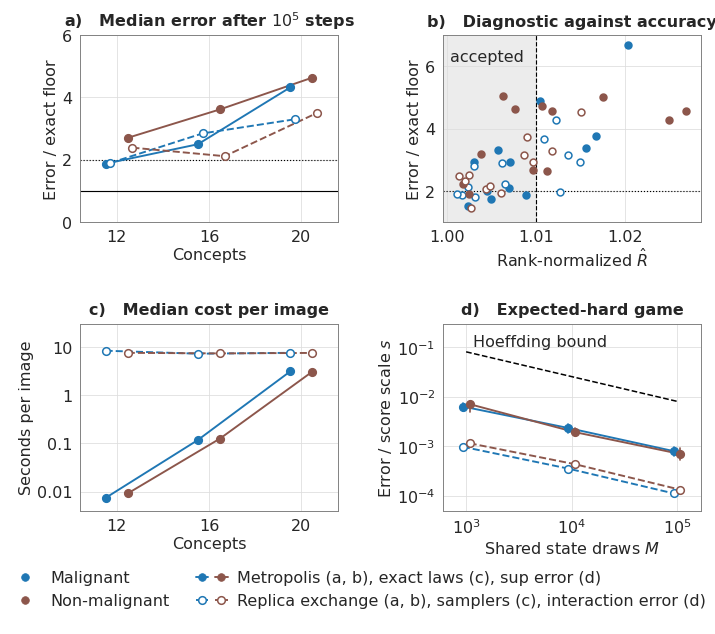

In [5]:
# ======================= Figure 3. Computation of local ranking laws =======================
s = csv(A, "e1_sampler")
s["ratio"] = s.max_error_P / s.max_error_P_iid
l = s[s.steps == s.steps.max()].copy()
NS = (12, 16, 20)
SMP = (("metropolis", True, "-"), ("replica_exchange", False, "--"))
fig, ax, H = canvas(2, legend_rows=2)
a = ax[0, 0]
for pop in POPS:
    for smp, fill, ls in SMP:
        med = [l[(l.n == n) & (l.sampler == smp) & (l.population == pop)].ratio.median() for n in NS]
        xs = np.arange(3) + OFF[pop] * (1 if fill else 1.0) + (0.0 if fill else 0.05)
        a.plot(xs, med, ls=ls, color=PCOL[pop], lw=2.5, zorder=3)
        dot(a, xs, med, PCOL[pop], fill)
a.axhline(1, color=BLACK, lw=1.5)
a.axhline(2, color=BLACK, lw=1.5, ls=":")
a.set_xticks(range(3), ["12", "16", "20"]); a.set_xlim(-0.4, 2.4); a.set_ylim(0, 6)
a.set_xlabel("Concepts"); a.set_ylabel("Error / exact floor")
a.set_title(r"a)   Median error after $10^5$ steps")
a = ax[0, 1]
a.axvspan(0.9995, 1.01, ymin=0, ymax=1, color=SHADE, zorder=0)
for pop in POPS:
    for smp, fill, _ in SMP:
        d = l[(l.sampler == smp) & (l.population == pop)]
        dot(a, d.rhat_rank, d.ratio, PCOL[pop], fill, ms=9)
a.axvline(1.01, color=BLACK, lw=1.5, ls="--")
a.axhline(2, color=BLACK, lw=1.5, ls=":")
a.set_xlim(0.9995, 1.0285); a.set_ylim(1, 7)
a.set_xticks([1.0, 1.01, 1.02], ["1.00", "1.01", "1.02"])
a.text(1.0003, 6.55, "accepted", fontsize=FS, va="top")
a.set_xlabel(r"Rank-normalized $\hat R$"); a.set_ylabel("Error / exact floor")
a.set_title(r"b)   Diagnostic against accuracy")
a = ax[1, 0]
for pop in POPS:
    ex = [l[(l.n == n) & (l.population == pop)].drop_duplicates("image").seconds_exact.median() for n in NS]
    sm = [l[(l.n == n) & (l.population == pop)].seconds_sampler_total.median() for n in NS]
    xs = np.arange(3) + OFF[pop]
    a.plot(xs, ex, color=PCOL[pop], lw=2.5); dot(a, xs, ex, PCOL[pop], True)
    a.plot(xs, sm, color=PCOL[pop], lw=2.5, ls="--"); dot(a, xs, sm, PCOL[pop], False)
a.set_yscale("log"); a.set_ylim(0.004, 30)
a.set_yticks([0.01, 0.1, 1, 10], ["0.01", "0.1", "1", "10"]); no_minor(a)
a.set_xticks(range(3), ["12", "16", "20"]); a.set_xlim(-0.4, 2.4)
a.set_xlabel("Concepts"); a.set_ylabel("Seconds per image")
a.set_title("c)   Median cost per image")
a = ax[1, 1]
eh = pd.read_csv(IMAGE_LEVEL + "e1_expected_hard_images.csv")
Ms = np.array([1e3, 1e4, 1e5])
hb = [eh[eh.draws == M].hoeffding_sup_bound_over_s.iloc[0] for M in Ms]
a.plot(Ms, hb, color=BLACK, lw=2, ls="--")
a.text(1.15e3, hb[0] * 1.12, "Hoeffding bound", fontsize=FS, va="bottom")
for pop in POPS:
    med = [eh[(eh.draws == M) & (eh.population == pop)].sup_error_over_s.median() for M in Ms]
    medI = [eh[(eh.draws == M) & (eh.population == pop)].banzhaf_interaction_error_over_s.median() for M in Ms]
    fx = 1.08 if pop == "non_malignant" else 0.93
    for k, M in enumerate(Ms):
        d = eh[(eh.draws == M) & (eh.population == pop)]
        a.plot([M * fx] * 2, np.percentile(d.sup_error_over_s, [25, 75]), color=PCOL[pop], lw=2.2)
    a.plot(Ms * fx, med, color=PCOL[pop], lw=2.5); dot(a, Ms * fx, med, PCOL[pop], True)
    a.plot(Ms * fx, medI, color=PCOL[pop], lw=2.5, ls="--"); dot(a, Ms * fx, medI, PCOL[pop], False)
a.set_xscale("log"); a.set_yscale("log"); a.set_xlim(6e2, 1.7e5); a.set_ylim(5e-5, 0.3)
a.set_xticks(Ms, [r"$10^3$", r"$10^4$", r"$10^5$"]); no_minor(a, "x")
a.set_xlabel("Shared state draws $M$"); a.set_ylabel("Error / score scale $s$")
a.set_title("d)   Expected-hard game")
h = POP_HANDLES + [both(lw=2.5, marker="o", ms=MS), both(lw=2.5, ls="--", marker="o", ms=MS, mfc="white", mew=2)]
legend_below(fig, H, h, POP_LABELS + ["Metropolis (a, b), exact laws (c), sup error (d)",
                                      "Replica exchange (a, b), samplers (c), interaction error (d)"], 2)
save(fig, "fig2_computation")
display(Image(PNG + "fig2_computation.png"))

### Figure 4. Non-additivity and its parity

saved fig3_parity


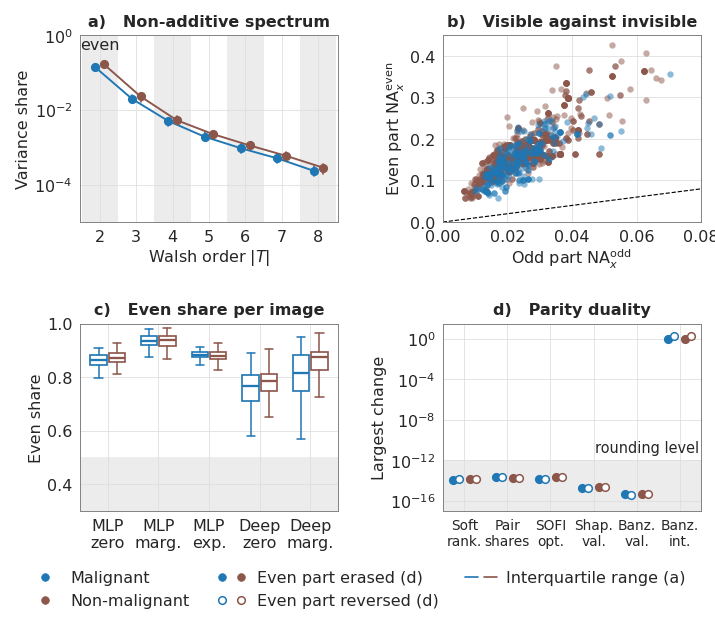

In [6]:
# ======================= Figure 4. Non-additivity and its parity =======================
im = pd.read_csv(IMAGE_LEVEL + "tuned_images.csv")
im["even_share"] = np.where(im.NA > 1e-9, im.NA_even / im.NA.where(im.NA > 0, 1), np.nan)
fig, ax, H = canvas(2, legend_rows=2)
a = ax[0, 0]
orders = np.arange(2, 9)
for k in orders:
    if k % 2 == 0:
        a.axvspan(k - 0.5, k + 0.5, color=SHADE, lw=0, zorder=0)
mz = im[(im["head"] == "V12_mlp") & (im.game == "zero")]
for pop in POPS:
    d = mz[mz.population == pop]
    xs = orders + OFF[pop]
    meds = [iqr_dot(a, x, d[f"order{k}"], PCOL[pop]) for x, k in zip(xs, orders)]
    a.plot(xs, meds, color=PCOL[pop], lw=2.5, zorder=3)
a.set_yscale("log"); a.set_xticks(orders); a.set_xlim(1.45, 8.55); a.set_ylim(1e-5, 1)
a.set_yticks([1e-4, 1e-2, 1]); no_minor(a)
a.text(2, 0.42, "even", ha="center", fontsize=FS)
a.set_xlabel("Walsh order $|T|$"); a.set_ylabel("Variance share")
a.set_title("a)   Non-additive spectrum")
a = ax[0, 1]
for pop in ("non_malignant", "malignant"):
    d = mz[mz.population == pop]
    a.scatter(d.NA_odd, d.NA_even, s=SC, color=PCOL[pop], alpha=0.5, linewidths=0, zorder=3)
a.plot([0, 0.5], [0, 0.5], color=BLACK, lw=1.5, ls="--")
a.set_xlim(0, 0.08); a.set_ylim(0, 0.45)
a.set_xlabel(r"Odd part $\mathrm{NA}^{\mathrm{odd}}_x$"); a.set_ylabel(r"Even part $\mathrm{NA}^{\mathrm{even}}_x$")
a.set_title("b)   Visible against invisible")
a = ax[1, 0]
cfgs = [("V12_mlp", "zero"), ("V12_mlp", "marginal"), ("V12_mlp", "expected_zero"), ("V12_deep", "zero"),
        ("V12_deep", "marginal")]
clab = ["MLP\nzero", "MLP\nmarg.", "MLP\nexp.", "Deep\nzero", "Deep\nmarg."]
a.axhspan(0, 0.5, color=SHADE, zorder=0)
for i, (hd, gm) in enumerate(cfgs):
    for pop in POPS:
        d = im[(im["head"] == hd) & (im.game == gm) & (im.population == pop)]
        box(a, d.even_share, i + 1.5 * OFF[pop], PCOL[pop])
a.set_xticks(range(5), clab); a.set_xlim(-0.55, 4.55); a.set_ylim(0.3, 1.0)
a.set_ylabel("Even share"); a.set_title("c)   Even share per image")
a = ax[1, 1]
inv = csv(A, "e2_invisibility_full")
inv = inv[inv["head"] == "V12_mlp"]
cols = [("soft_ranking_change", "Soft\nrank."), ("pair_share_change", "Pair\nshares"),
        ("sofi_optimum_change", "SOFI\nopt."), ("shapley_change", "Shap.\nval."),
        ("banzhaf_value_change", "Banz.\nval."), ("banzhaf_interaction_relative_change_median", "Banz.\nint.")]
a.axhspan(1e-18, 1e-12, color=SHADE, zorder=0)
a.text(5.45, 3e-12, "rounding level", fontsize=FS - 2, ha="right", va="bottom")
for i, (cname, _) in enumerate(cols):
    for pop in POPS:
        for tw, fill, dx in (("even part erased", True, -0.07), ("even part reversed", False, 0.07)):
            v = inv[(inv.twin == tw) & (inv.population == pop)][cname].max()
            dot(a, i + 1.6 * OFF[pop] + dx, max(v, 1e-17), PCOL[pop], fill)
a.set_yscale("log"); a.set_ylim(1e-17, 30); a.set_yticks([1e-16, 1e-12, 1e-8, 1e-4, 1]); no_minor(a)
a.set_xticks(range(len(cols)), [lab for _, lab in cols], fontsize=FS - 3); a.set_xlim(-0.5, 5.5)
a.set_ylabel("Largest change"); a.set_title("d)   Parity duality")
h = POP_HANDLES + [both(marker="o", ls="", ms=MS), both(marker="o", ls="", ms=MS, mfc="white", mew=2),
                   both(lw=2.2)]
legend_below(fig, H, h, POP_LABELS + ["Even part erased (d)", "Even part reversed (d)", "Interquartile range (a)"], 3)
save(fig, "fig3_parity")
display(Image(PNG + "fig3_parity.png"))

### Figure 5. Decisions and other pair indices

saved fig4_decisions


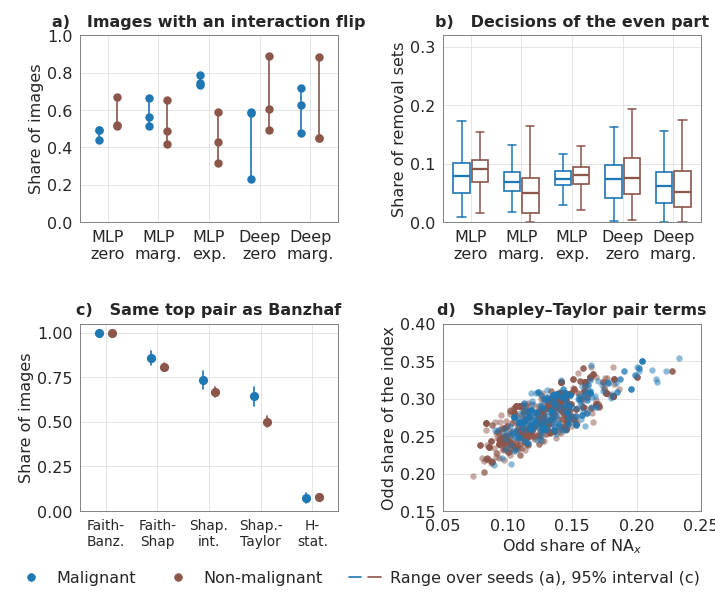

In [7]:
# ======================= Figure 5. Decisions and other pair indices =======================
de = csv(A, "e2_decisions")
ix = pd.read_csv(IMAGE_LEVEL + "tuned_indices.csv")
fig, ax, H = canvas(2, legend_rows=1)
a = ax[0, 0]
for i, (hd, gm) in enumerate(cfgs):
    for pop in POPS:
        d = de[(de["head"] == hd) & (de.game == gm) & (de.population == pop)]
        x = i + 1.5 * OFF[pop]
        a.plot([x, x], [d.interaction_flip_images.min(), d.interaction_flip_images.max()], color=PCOL[pop], lw=2.2)
        dot(a, [x] * len(d), d.interaction_flip_images, PCOL[pop], True, ms=9)
a.set_xticks(range(5), clab); a.set_xlim(-0.55, 4.55); a.set_ylim(0, 1)
a.set_ylabel("Share of images"); a.set_title("a)   Images with an interaction flip")
a = ax[0, 1]
for i, (hd, gm) in enumerate(cfgs):
    for pop in POPS:
        d = im[(im["head"] == hd) & (im.game == gm) & (im.population == pop)]
        box(a, d.even_change, i + 1.5 * OFF[pop], PCOL[pop])
a.set_xticks(range(5), clab); a.set_xlim(-0.55, 4.55); a.set_ylim(0, 0.32)
a.set_ylabel("Share of removal sets"); a.set_title("b)   Decisions of the even part")
a = ax[1, 0]
MN = [("faith_banzhaf", "Faith-\nBanz."), ("faith_shap", "Faith-\nShap"), ("shapley_interaction", "Shap.\nint."),
      ("shapley_taylor", "Shap.-\nTaylor"), ("h_statistic", "H-\nstat.")]
for i, (m, _) in enumerate(MN):
    for pop in POPS:
        d = ix[(ix["head"] == "V12_mlp") & (ix.population == pop) & (ix.method == m)].top_agree.astype(float).values
        boot = [RNG.choice(d, len(d)).mean() for _ in range(2000)]
        x = i + OFF[pop]
        a.plot([x, x], np.percentile(boot, [2.5, 97.5]), color=PCOL[pop], lw=2.2)
        dot(a, x, d.mean(), PCOL[pop], True)
a.set_xticks(range(5), [lab for _, lab in MN], fontsize=FS - 3); a.set_xlim(-0.5, 4.5); a.set_ylim(0, 1.05)
a.set_ylabel("Share of images"); a.set_title("c)   Same top pair as Banzhaf")
a = ax[1, 1]
st = ix[ix.method == "shapley_taylor"][["seed", "head", "population", "image", "st_odd_share"]]
z = im[im.game == "zero"].merge(st, on=["seed", "head", "population", "image"])
z["odd_frac"] = z.NA_odd / z.NA
for pop in ("non_malignant", "malignant"):
    d = z[(z["head"] == "V12_mlp") & (z.population == pop)]
    a.scatter(d.odd_frac, d.st_odd_share, s=SC, color=PCOL[pop], alpha=0.5, linewidths=0, zorder=3)
a.set_xlim(0.05, 0.25); a.set_ylim(0.15, 0.4)
a.set_xlabel(r"Odd share of $\mathrm{NA}_x$"); a.set_ylabel("Odd share of the index")
a.set_title("d)   Shapley–Taylor pair terms")
h = POP_HANDLES + [both(lw=2.2)]
legend_below(fig, H, h, POP_LABELS + ["Range over seeds (a), 95% interval (c)"], 3)
save(fig, "fig4_decisions")
display(Image(PNG + "fig4_decisions.png"))

### Figure 7. Pair certificates across retrained models, removal rules and model families (file fig5_pairs.pdf)

saved fig5_pairs


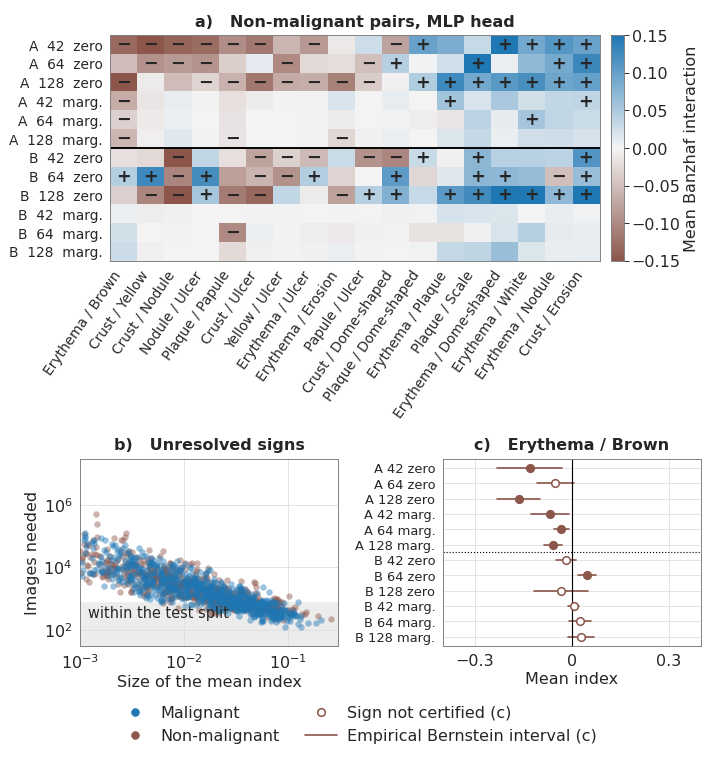

In [8]:
# ======================= Figure 7. Pair certificates across retrained models, removal rules and model families (file fig5_pairs.pdf) =======================
ca, cb = csv(A, "e2_certificates"), csv(B, "e2_certificates")
ca["recipe"], cb["recipe"] = "A", "B"
cc = pd.concat([ca, cb])
cc = cc[(cc.quantity == "banzhaf_interaction") & (cc["head"] == "V12_mlp") & (cc.population == "non_malignant") &
        cc.game.isin(["zero", "marginal"])]
cert_any = cc[(cc.recipe == "A") & (cc.bernstein_sign != 0)].pair.value_counts()
keep = cert_any[cert_any >= 2].index.tolist()
order = cc[(cc.recipe == "A") & cc.pair.isin(keep)].groupby("pair")["mean"].mean().sort_values().index.tolist()
rows = [(r, sd, gm) for r in ("A", "B") for gm in ("zero", "marginal") for sd in (42, 64, 128)]
M = np.full((len(rows), len(order)), np.nan)
S = np.zeros_like(M)
for i, (r, sd, gm) in enumerate(rows):
    d = cc[(cc.recipe == r) & (cc.seed == sd) & (cc.game == gm)].set_index("pair")
    for j, p in enumerate(order):
        M[i, j] = d.loc[p, "mean"]
        S[i, j] = d.loc[p, "bernstein_sign"]
TOPH = 7.7
fig, ax, H = canvas(1, top_extra=TOPH, legend_rows=2)
ah = fig.add_axes([2.0 / CANVAS_W, (H - 0.65 - 4.1) / H, 8.9 / CANVAS_W, 4.1 / H])
cm = LinearSegmentedColormap.from_list("div", [BROWN, "#f4f4f4", BLUE])
im_ = ah.imshow(M, cmap=cm, vmin=-0.15, vmax=0.15, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if S[i, j] != 0:
            ah.text(j, i, "+" if S[i, j] > 0 else "−", ha="center", va="center", fontsize=FS + 2, fontweight="bold")
ah.set_yticks(range(len(rows)), [f"{r}  {sd}  {'zero' if gm == 'zero' else 'marg.'}" for r, sd, gm in rows],
              fontsize=FS - 3)
ah.set_xticks(range(len(order)), order, rotation=55, ha="right", fontsize=FS - 3)
ah.axhline(5.5, color=BLACK, lw=2.5)
ah.grid(False)
cax = fig.add_axes([11.1 / CANVAS_W, (H - 0.65 - 4.1) / H, 0.25 / CANVAS_W, 4.1 / H])
cbar = fig.colorbar(im_, cax=cax)
cbar.set_label("Mean Banzhaf interaction")
ah.set_title("a)   Non-malignant pairs, MLP head")
a = ax[0, 0]
d = ca[(ca.quantity == "banzhaf_interaction") & ca["head"].isin(["V12_mlp", "V12_deep"]) &
       ca.game.isin(["zero", "marginal"]) & (ca.bernstein_sign == 0)].copy()
d["need"] = pd.to_numeric(d.images_needed_bernstein, errors="coerce")
a.axhspan(10, 774, color=SHADE, zorder=0)
for pop in ("non_malignant", "malignant"):
    e = d[d.population == pop]
    a.scatter(e["mean"].abs(), e.need, s=SC, color=PCOL[pop], alpha=0.45, linewidths=0, zorder=3)
a.set_xscale("log"); a.set_yscale("log"); a.set_xlim(1e-3, 0.3); a.set_ylim(30, 3e7)
a.set_yticks([1e2, 1e4, 1e6]); no_minor(a); no_minor(a, "x")
a.text(1.2e-3, 600, "within the test split", fontsize=FS - 2, va="top")
a.set_xlabel("Size of the mean index"); a.set_ylabel("Images needed")
a.set_title("b)   Unresolved signs")
a = ax[0, 1]
EB = pd.concat([ca, cb])
EB = EB[(EB.quantity == "banzhaf_interaction") & (EB["head"] == "V12_mlp") & (EB.population == "non_malignant") &
        (EB.pair == "Erythema / Brown") & EB.game.isin(["zero", "marginal"])]
rows2 = [(r, gm, sd) for r in ("A", "B") for gm in ("zero", "marginal") for sd in (42, 64, 128)]
for k, (r, gm, sd) in enumerate(rows2):
    e = EB[(EB.recipe == r) & (EB.game == gm) & (EB.seed == sd)].iloc[0]
    a.plot([e["mean"] - e.bernstein_radius, e["mean"] + e.bernstein_radius], [k, k], color=BROWN, lw=2.2)
    dot(a, e["mean"], k, BROWN, e.bernstein_sign != 0)
a.axvline(0, color=BLACK, lw=1.5)
a.axhline(5.5, color=BLACK, lw=1.5, ls=":")
a.set_ylim(11.6, -0.6); a.set_xlim(-0.4, 0.4)
a.set_yticks(range(12), [f"{r} {sd} {'zero' if gm == 'zero' else 'marg.'}" for r, gm, sd in rows2], fontsize=FS - 4)
a.set_xticks([-0.3, 0, 0.3], ["−0.3", "0", "0.3"])
a.set_xlabel("Mean index"); a.set_title("c)   Erythema / Brown")
h = POP_HANDLES + [Line2D([], [], marker="o", ls="", ms=MS, mfc="white", mec=BROWN, mew=2),
                   Line2D([], [], color=BROWN, lw=2.2)]
legend_below(fig, H, h, POP_LABELS + ["Sign not certified (c)", "Empirical Bernstein interval (c)"], 2)
save(fig, "fig5_pairs")
display(Image(PNG + "fig5_pairs.png"))

### Figure 6. Compact summaries of local ranking laws (file fig6_summaries.pdf)

saved fig6_summaries


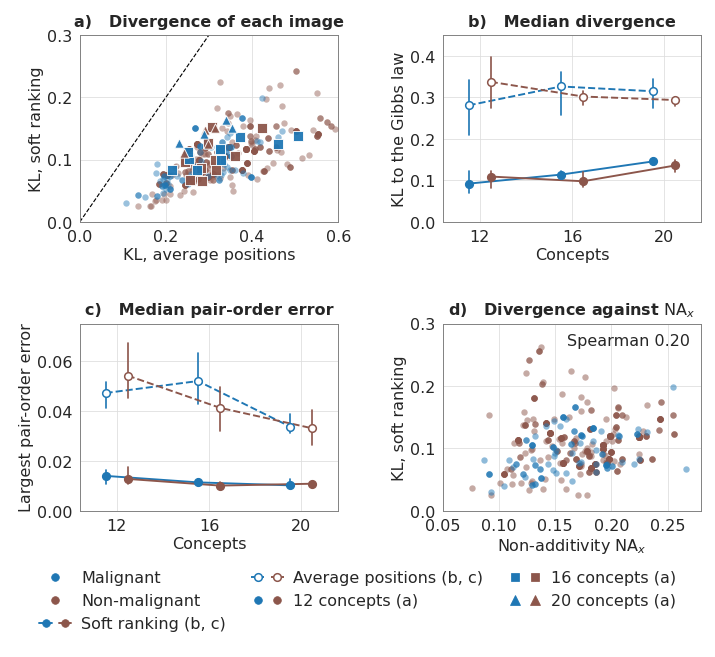

In [9]:
# ======================= Figure 6. Compact summaries of local ranking laws (file fig6_summaries.pdf) =======================
e3 = csv(A, "e3_summaries")
e3["ratio"] = e3.kl_average_position_fit / e3.kl_soft_ranking_fit
MK = {12: "o", 16: "s", 20: "^"}
fig, ax, H = canvas(2, legend_rows=3)
a = ax[0, 0]
for n in (12, 16, 20):
    for pop in ("non_malignant", "malignant"):
        d = e3[(e3.n == n) & (e3.population == pop)]
        a.scatter(d.kl_average_position_fit, d.kl_soft_ranking_fit, s=SC if n == 12 else 150, marker=MK[n],
                  color=PCOL[pop], alpha=0.45 if n == 12 else 0.95, linewidths=0 if n == 12 else 1.2,
                  edgecolors="white", zorder=3 if n == 12 else 4)
a.plot([0, 0.6], [0, 0.6], color=BLACK, lw=1.5, ls="--")
a.set_xlim(0, 0.6); a.set_ylim(0, 0.3)
a.set_xlabel("KL, average positions"); a.set_ylabel("KL, soft ranking")
a.set_title("a)   Divergence of each image")
for k, (cP, cY, ylab, title, ylim) in enumerate(
        (("kl_soft_ranking_fit", "kl_average_position_fit", "KL to the Gibbs law", "b)   Median divergence", (0, 0.45)),
         ("pair_error_soft_ranking_fit", "pair_error_average_position_fit", "Largest pair-order error",
          "c)   Median pair-order error", (0, 0.075)))):
    a = ax[0, 1] if k == 0 else ax[1, 0]
    for pop in POPS:
        for cname, fill, ls in ((cP, True, "-"), (cY, False, "--")):
            xs = np.arange(3) + OFF[pop]
            meds = [iqr_dot(a, x, e3[(e3.n == n) & (e3.population == pop)][cname], PCOL[pop], fill)
                    for x, n in zip(xs, (12, 16, 20))]
            a.plot(xs, meds, color=PCOL[pop], lw=2.5, ls=ls, zorder=3)
    a.set_xticks(range(3), ["12", "16", "20"]); a.set_xlim(-0.4, 2.4); a.set_ylim(*ylim)
    a.set_xlabel("Concepts"); a.set_ylabel(ylab); a.set_title(title)
a = ax[1, 1]
d12 = e3[e3.n == 12]
for pop in ("non_malignant", "malignant"):
    e = d12[d12.population == pop]
    a.scatter(e.NA, e.kl_soft_ranking_fit, s=SC, color=PCOL[pop], alpha=0.5, linewidths=0, zorder=3)
rho = spearmanr(d12.NA, d12.kl_soft_ranking_fit)[0]
a.text(0.27, 0.285, rf"Spearman {rho:.2f}", fontsize=FS, ha="right", va="top")
a.set_xlim(0.05, 0.28); a.set_ylim(0, 0.3)
a.set_xlabel(r"Non-additivity $\mathrm{NA}_x$"); a.set_ylabel("KL, soft ranking")
a.set_title(r"d)   Divergence against $\mathrm{NA}_x$")
h = POP_HANDLES + [both(lw=2.5, marker="o", ms=MS), both(lw=2.5, ls="--", marker="o", ms=MS, mfc="white", mew=2),
                   both(marker="o", ls="", ms=MS), both(marker="s", ls="", ms=MS + 1), both(marker="^", ls="", ms=MS + 2)]
legend_below(fig, H, h, ["Malignant", "Non-malignant", "Soft ranking (b, c)", "Average positions (b, c)",
                         "12 concepts (a)", "16 concepts (a)", "20 concepts (a)"], 3)
save(fig, "fig6_summaries")
display(Image(PNG + "fig6_summaries.png"))

## Tables 1 to 5

In [10]:
# ============================================================
# TABLES 1 TO 5
# Every cell is recomputed from the result files and written as the LaTeX block of the manuscript. The generated
# blocks are then compared, character for character, with the blocks printed in the manuscript (MANUSCRIPT_TABLES).
# ============================================================
import json
import numpy as np
import pandas as pd

TABLE_DIR = os.path.join(OUTPUT_DIR, "tables")
os.makedirs(TABLE_DIR, exist_ok=True)


def rcsv(fam, name):
    return pd.read_csv(f"{RESULTS}/{fam}/csv/{name}.csv", keep_default_na=False, na_values=[""])


def latex_sci(x):
    m, e = f"{x:.1e}".split("e")
    return rf"\({m}\times10^{{{int(e)}}}\)"


# ---------------- Table 1. Test performance ----------------
tm = {fam: pd.read_csv(f"{RESULTS}/{fam}/training_metrics.csv") for fam in ("tuned", "baseline")}


def ms(fam, model, col):
    t = tm[fam]
    if col not in t.columns:                                     # the baseline run stored no concept AUROC
        return "n/a"
    v = t[(t.split == "test") & (t.model == model)][col]
    return f"{v.mean():.3f} ({v.std():.3f})"                       # mean (sample standard deviation) over models


rows1 = []
for model, label in (("V12_affine", "V12 affine"), ("V12_mlp", "V12 MLP"), ("V12_deep", "V12 deep"),
                     ("V16_mlp", "V16 MLP"), ("V20_mlp", "V20 MLP")):
    rows1.append(f"{label} & {ms('tuned', model, 'auroc')} & {ms('tuned', model, 'balanced_accuracy')} & "
                 f"{ms('baseline', model, 'auroc')} & {ms('baseline', model, 'balanced_accuracy')} \\\\")
rows1.append(f"Concepts & {ms('tuned', 'concepts', 'concept_macro_auroc')} & {ms('tuned', 'concepts', 'concept_balanced_accuracy')} & "
             f"{ms('baseline', 'concepts', 'concept_macro_auroc')} & {ms('baseline', 'concepts', 'concept_balanced_accuracy')} \\\\")
table1 = "\n".join(rows1)

# ---------------- Table 2. Main findings of both families ----------------


def findings(fam):
    ct, dc = rcsv(fam, "e2_controls"), rcsv(fam, "e2_decisions")
    iv, ix = rcsv(fam, "e2_invisibility_full"), rcsv(fam, "e2_indices_full")
    ss, e3 = rcsv(fam, "e1_sampler_summary"), rcsv(fam, "e3_summaries")
    nl = ct[ct["head"].isin(["V12_mlp", "V12_deep"])]
    rng = lambda s, d: f"{s.min():.{d}f} to {s.max():.{d}f}"
    flips = dc[dc["head"].isin(["V12_mlp", "V12_deep"])].interaction_flip_images
    st = ix[ix.method == "shapley_taylor"].odd_part_norm_share
    mh = ss[ss.sampler == "metropolis"].median_ratio
    soft = e3[e3.n == 12].groupby("population").kl_soft_ranking_fit.median()
    avg = e3[e3.n == 12].groupby("population").kl_average_position_fit.median()
    sig2 = lambda x: f"{x:.{max(0, 1 - int(np.floor(np.log10(abs(x)))))}f}"     # two significant digits
    span = lambda s: sig2(s.min()) if sig2(s.min()) == sig2(s.max()) else f"{sig2(s.min())} to {sig2(s.max())}"
    soft_txt, avg_txt = span(soft), span(avg)
    p4, cnt = rcsv(fam, "e4_persistent"), rcsv(fam, "e4_counts")
    return [
        latex_sci(ct[ct["head"] == "V12_affine"].NA_max.max()),
        f"{100 * nl.certified_non_additive.min():.0f}\\%",
        rng(ct[ct["head"] == "V12_mlp"].even_share_mean, 2),
        rng(ct[ct["head"] == "V12_deep"].even_share_mean, 2),
        latex_sci(iv[["soft_ranking_change", "pair_share_change", "sofi_optimum_change"]].max().max()),
        f"{100 * flips.min():.0f}\\% to {100 * flips.max():.0f}\\%",
        rng(st, 2),
        rng(mh, 1),
        f"{int(ss.rhat_passes.sum())}, {int(ss.inaccurate_passes.sum())}",
        f"{soft_txt} against {avg_txt}",
        f"{len(p4)}",
        f"{int(cnt.persistent.sum())}",
    ]


labels2 = [r"Affine head additive (largest \(\mathrm{NA}_x\))", "Images certified non-additive (MLP, deep)",
           "Mean even share, MLP head", "Mean even share, deep head",
           "Largest change of ranking quantities after even erasure", "Images with an interaction flip (MLP, deep)",
           "Odd share of Shapley-Taylor pair terms (median image)",
           "Metropolis error over floor, 12 to 20 concepts (best-performing models)",
           r"\(\hat R\) passes, inaccurate passes (of 48 runs, best-performing models)",
           "Soft ranking against average positions, median divergence on V12 (best-performing models)",
           "Persistent structural findings", "Persistent pair indices"]
fa, fb = findings("tuned"), findings("baseline")
table2 = "\n".join(f"{l} & {a} & {b} \\\\" for l, a, b in zip(labels2, fa, fb))

# ---------------- Table 3 of the report. Content of the population report ----------------
rep = json.load(open(f"{RESULTS}/tuned/run_info.json"))["selected_seed"]
ct, dc = rcsv("tuned", "e2_controls"), rcsv("tuned", "e2_decisions")
r0 = ct[(ct.seed == rep) & (ct["head"] == "V12_mlp") & (ct.game == "zero")].set_index("population")
d0 = dc[(dc.seed == rep) & (dc["head"] == "V12_mlp") & (dc.game == "zero")].set_index("population")
w = r0.N / r0.N.sum()
na_m, na_n = 100 * r0.NA_mean["malignant"], 100 * r0.NA_mean["non_malignant"]
even = 100 * (r0.even_share_mean * w).sum()
change = 100 * (d0.even_erasure_decision_change_mean * w).sum()
table3 = "\n".join([
    r"No additive rule reproduces the movement & Certified \(\mathrm{NA}_x>0\), with \(\sqrt{\hat H}>\varepsilon\) & Proposition~\ref{result:5}(i),(iv) \\",
    rf"An additive rule misses {na_m:.0f}\% and {na_n:.0f}\% & Mean of \(\mathrm{{NA}}_x\) & Proposition~\ref{{result:5}}(i) \\",
    rf"{even:.0f}\% comes from joint effects that rankings miss & Mean even share & Proposition~\ref{{result:9}}(vi), Proposition~\ref{{result:6}} \\",
    rf"Removing joint effects changes {change:.0f}\% of decisions & Even decision change & Section~\ref{{sec:decision}}, Corollary~\ref{{result:7}} \\",
    r"\emph{Plaque}, \emph{ulcer} and \emph{crust} carry the largest visible loads & Odd loads of concepts & Section~\ref{sec:certificates} \\",
    r"\emph{Crust} carries the largest share of joint effects & Even loads of concepts & Section~\ref{sec:certificates} \\",
    r"Absent \emph{crust} and absent \emph{ulcer} overlap & Certified negative index, positive effects & Section~\ref{sec:certificates} \\",
    r"Absent \emph{crust} and \emph{erosion} matter together & Certified positive index, positive effects & Section~\ref{sec:certificates} \\",
    r"No label for malignant images & Images needed for the effects & Section~\ref{sec:certificates} \\",
    r"Probabilities exact up to rounding & Forward-backward recursions over \(2^C\) & Proposition~\ref{result:2}(i) \\",
    r"Simulation less accurate, approved by its check & Error over the exact floor, \(\hat R\) & Proposition~\ref{result:2}(ii) \\",
    r"Soft ranking keeps most, average positions less & Exact divergences of maximum-entropy fits & Proposition~\ref{result:9}(iv) \\",
])

for name, body in (("table1_performance", table1), ("table2_findings", table2), ("table3_report", table3)):
    with open(os.path.join(TABLE_DIR, name + ".tex"), "w") as fh:
        fh.write(body + "\n")
    print(f"--- {name} ---\n{body}\n")

# ---------------- Tables 4 and 5. Concepts in each half and labels of concept pairs ----------------
import pandas as pd
CL = pd.read_csv(f"{RESULTS}/concept_level/concept_loads.csv")
PL = pd.read_csv(f"{RESULTS}/concept_level/pair_labels.csv", keep_default_na=False)
NICE = {"Brown(Hyperpigmentation)": "hyperpigmentation", "White(Hypopigmentation)": "hypopigmentation"}
nice = lambda c: NICE.get(c, c.lower())
ORDER = ["Erythema", "Plaque", "Papule", "Brown(Hyperpigmentation)", "Scale", "Crust", "Yellow", "White(Hypopigmentation)",
         "Nodule", "Dome-shaped", "Erosion", "Ulcer"]
cl = CL[(CL.family == "tuned") & (CL["head"] == "V12_mlp") & CL.game.isin(["zero", "marginal"])]
agg = cl.groupby(["population", "concept"])[["present_share", "odd_load_mean", "even_load_mean"]].mean()
rows4 = []
for c in ORDER:
    m, b = agg.loc[("malignant", c)], agg.loc[("non_malignant", c)]
    rows4.append(rf"\emph{{{nice(c)}}} & {100 * m.present_share:.0f} & {100 * m.odd_load_mean:.1f} & {100 * m.even_load_mean:.1f} & "
                 rf"{100 * b.present_share:.0f} & {100 * b.odd_load_mean:.1f} & {100 * b.even_load_mean:.1f} \\")
table4 = "\n".join(rows4)

lab = PL[(PL.label != "") & (PL.population == "non_malignant")].copy()
lab["col"] = lab.family + "_" + lab["head"]
cnt = lab.groupby(["pair", "label", "col"]).size().unstack("col", fill_value=0)
for col in ("tuned_V12_mlp", "tuned_V12_deep", "baseline_V12_mlp", "baseline_V12_deep"):
    if col not in cnt:
        cnt[col] = 0
cnt["total"] = cnt.sum(axis=1)
cnt = cnt[cnt.total >= 2].reset_index().sort_values(["label", "total", "pair"], ascending=[False, False, True])
rows5 = []
for _, r in cnt.iterrows():
    a, b = r.pair.split(" / ")
    lbl = "Overlapping" if r.label == "overlapping" else "Only in combination"
    rows5.append(rf"\emph{{{nice(a)}}} with \emph{{{nice(b)}}} & {lbl} & {r.tuned_V12_mlp} & {r.tuned_V12_deep} & "
                 rf"{r.baseline_V12_mlp} & {r.baseline_V12_deep} \\")
table5 = "\n".join(rows5)
for name, body in (("table4_concepts", table4), ("table5_labels", table5)):
    with open(os.path.join(TABLE_DIR, name + ".tex"), "w") as fh:
        fh.write(body + "\n")
    print(f"--- {name} ---\n{body}\n")


--- table1_performance ---
V12 affine & 0.720 (0.015) & 0.648 (0.006) & 0.715 (0.009) & 0.644 (0.011) \\
V12 MLP & 0.737 (0.030) & 0.660 (0.023) & 0.722 (0.039) & 0.646 (0.023) \\
V12 deep & 0.728 (0.033) & 0.646 (0.041) & 0.718 (0.031) & 0.638 (0.021) \\
V16 MLP & 0.761 (0.023) & 0.690 (0.033) & 0.728 (0.024) & 0.666 (0.019) \\
V20 MLP & 0.804 (0.017) & 0.730 (0.022) & 0.779 (0.016) & 0.700 (0.010) \\
Concepts & 0.865 (0.003) & 0.772 (0.005) & n/a & 0.709 (0.010) \\

--- table2_findings ---
Affine head additive (largest \(\mathrm{NA}_x\)) & \(3.1\times10^{-31}\) & \(4.5\times10^{-31}\) \\
Images certified non-additive (MLP, deep) & 100\% & 100\% \\
Mean even share, MLP head & 0.86 to 0.96 & 0.85 to 0.96 \\
Mean even share, deep head & 0.72 to 0.87 & 0.77 to 0.92 \\
Largest change of ranking quantities after even erasure & \(2.2\times10^{-14}\) & \(1.4\times10^{-14}\) \\
Images with an interaction flip (MLP, deep) & 23\% to 89\% & 18\% to 92\% \\
Odd share of Shapley-Taylor pair terms 

In [11]:
MANUSCRIPT_TABLES = {'table1_performance': 'V12 affine & 0.720 (0.015) & 0.648 (0.006) & 0.715 (0.009) & 0.644 (0.011) \\\\\nV12 MLP & 0.737 (0.030) & 0.660 (0.023) & 0.722 (0.039) & 0.646 (0.023) \\\\\nV12 deep & 0.728 (0.033) & 0.646 (0.041) & 0.718 (0.031) & 0.638 (0.021) \\\\\nV16 MLP & 0.761 (0.023) & 0.690 (0.033) & 0.728 (0.024) & 0.666 (0.019) \\\\\nV20 MLP & 0.804 (0.017) & 0.730 (0.022) & 0.779 (0.016) & 0.700 (0.010) \\\\\nConcepts & 0.865 (0.003) & 0.772 (0.005) & n/a & 0.709 (0.010) \\\\', 'table2_findings': 'Affine head additive (largest \\(\\mathrm{NA}_x\\)) & \\(3.1\\times10^{-31}\\) & \\(4.5\\times10^{-31}\\) \\\\\nImages certified non-additive (MLP, deep) & 100\\% & 100\\% \\\\\nMean even share, MLP head & 0.86 to 0.96 & 0.85 to 0.96 \\\\\nMean even share, deep head & 0.72 to 0.87 & 0.77 to 0.92 \\\\\nLargest change of ranking quantities after even erasure & \\(2.2\\times10^{-14}\\) & \\(1.4\\times10^{-14}\\) \\\\\nImages with an interaction flip (MLP, deep) & 23\\% to 89\\% & 18\\% to 92\\% \\\\\nOdd share of Shapley-Taylor pair terms (median image) & 0.26 to 0.36 & 0.25 to 0.33 \\\\\nMetropolis error over floor, 12 to 20 concepts (best-performing models) & 2.1 to 4.6 & 2.9 to 4.7 \\\\\n\\(\\hat R\\) passes, inaccurate passes (of 48 runs, best-performing models) & 31, 22 & 23, 18 \\\\\nSoft ranking against average positions, median divergence on V12 (best-performing models) & 0.092 to 0.11 against 0.28 to 0.34 & 0.065 against 0.095 to 0.11 \\\\\nPersistent structural findings & 6 & 5 \\\\\nPersistent pair indices & 0 & 0 \\\\', 'table3_report': 'No additive rule reproduces the movement & Certified \\(\\mathrm{NA}_x>0\\), with \\(\\sqrt{\\hat H}>\\varepsilon\\) & Proposition~\\ref{result:5}(i),(iv) \\\\\nAn additive rule misses 16\\% and 18\\% & Mean of \\(\\mathrm{NA}_x\\) & Proposition~\\ref{result:5}(i) \\\\\n86\\% comes from joint effects that rankings miss & Mean even share & Proposition~\\ref{result:9}(vi), Proposition~\\ref{result:6} \\\\\nRemoving joint effects changes 8\\% of decisions & Even decision change & Section~\\ref{sec:decision}, Corollary~\\ref{result:7} \\\\\n\\emph{Plaque}, \\emph{ulcer} and \\emph{crust} carry the largest visible loads & Odd loads of concepts & Section~\\ref{sec:certificates} \\\\\n\\emph{Crust} carries the largest share of joint effects & Even loads of concepts & Section~\\ref{sec:certificates} \\\\\nAbsent \\emph{crust} and absent \\emph{ulcer} overlap & Certified negative index, positive effects & Section~\\ref{sec:certificates} \\\\\nAbsent \\emph{crust} and \\emph{erosion} matter together & Certified positive index, positive effects & Section~\\ref{sec:certificates} \\\\\nNo label for malignant images & Images needed for the effects & Section~\\ref{sec:certificates} \\\\\nProbabilities exact up to rounding & Forward-backward recursions over \\(2^C\\) & Proposition~\\ref{result:2}(i) \\\\\nSimulation less accurate, approved by its check & Error over the exact floor, \\(\\hat R\\) & Proposition~\\ref{result:2}(ii) \\\\\nSoft ranking keeps most, average positions less & Exact divergences of maximum-entropy fits & Proposition~\\ref{result:9}(iv) \\\\', 'table4_concepts': '\\emph{erythema} & 65 & 5.7 & 1.1 & 63 & 5.1 & 1.6 \\\\\n\\emph{plaque} & 44 & 13.1 & 1.5 & 56 & 7.3 & 1.7 \\\\\n\\emph{papule} & 41 & 3.3 & 0.9 & 41 & 5.9 & 1.0 \\\\\n\\emph{hyperpigmentation} & 44 & 7.6 & 1.2 & 33 & 9.0 & 1.4 \\\\\n\\emph{scale} & 34 & 2.9 & 0.9 & 35 & 2.1 & 1.0 \\\\\n\\emph{crust} & 65 & 12.4 & 2.0 & 14 & 8.0 & 1.9 \\\\\n\\emph{yellow} & 25 & 2.9 & 0.7 & 10 & 1.2 & 0.7 \\\\\n\\emph{hypopigmentation} & 3 & 7.4 & 0.7 & 31 & 22.4 & 1.2 \\\\\n\\emph{nodule} & 48 & 9.8 & 1.0 & 24 & 4.1 & 1.2 \\\\\n\\emph{dome-shaped} & 19 & 2.3 & 0.5 & 18 & 4.9 & 0.8 \\\\\n\\emph{erosion} & 68 & 7.6 & 1.1 & 21 & 12.9 & 1.0 \\\\\n\\emph{ulcer} & 36 & 12.5 & 0.8 & 2 & 3.4 & 0.4 \\\\', 'table5_labels': '\\emph{crust} with \\emph{ulcer} & Overlapping & 4 & 1 & 4 & 1 \\\\\n\\emph{crust} with \\emph{nodule} & Overlapping & 1 & 0 & 4 & 0 \\\\\n\\emph{erosion} with \\emph{ulcer} & Overlapping & 2 & 0 & 2 & 1 \\\\\n\\emph{scale} with \\emph{erosion} & Overlapping & 2 & 0 & 2 & 0 \\\\\n\\emph{yellow} with \\emph{ulcer} & Overlapping & 1 & 0 & 2 & 1 \\\\\n\\emph{nodule} with \\emph{erosion} & Overlapping & 1 & 0 & 2 & 0 \\\\\n\\emph{yellow} with \\emph{nodule} & Overlapping & 1 & 0 & 2 & 0 \\\\\n\\emph{crust} with \\emph{yellow} & Overlapping & 1 & 0 & 0 & 1 \\\\\n\\emph{scale} with \\emph{crust} & Overlapping & 0 & 0 & 2 & 0 \\\\\n\\emph{scale} with \\emph{nodule} & Overlapping & 0 & 0 & 2 & 0 \\\\\n\\emph{crust} with \\emph{erosion} & Only in combination & 5 & 0 & 3 & 0 \\\\\n\\emph{crust} with \\emph{yellow} & Only in combination & 0 & 0 & 2 & 0 \\\\\n\\emph{erosion} with \\emph{ulcer} & Only in combination & 0 & 0 & 2 & 0 \\\\\n\\emph{nodule} with \\emph{ulcer} & Only in combination & 0 & 0 & 2 & 0 \\\\'}

for name, block in MANUSCRIPT_TABLES.items():
    rebuilt = open(os.path.join(TABLE_DIR, name + ".tex")).read().strip()
    assert rebuilt == block.strip(), f"{name} differs from the manuscript"
    print(f"{name}: identical to the manuscript")

table1_performance: identical to the manuscript
table2_findings: identical to the manuscript
table3_report: identical to the manuscript
table4_concepts: identical to the manuscript
table5_labels: identical to the manuscript


## Every number of the text

Each row recomputes one printed value. The section labels follow the manuscript. A failed check raises an error.

In [12]:
# ============================================================
# EVERY NUMBER OF THE TEXT, RECOMPUTED FROM THE RESULT FILES
# Each check recomputes one value, formats it as printed in the manuscript and compares the two strings.
# A failed check stops the notebook, so a complete run certifies every number listed below.
# ============================================================
import json, os, re
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

RES = RESULTS
LOG = []


def load(fam, name):
    return pd.read_csv(f"{RES}/{fam}/csv/{name}.csv", keep_default_na=False, na_values=[""])


def _plain(v):
    if isinstance(v, (tuple, list)):
        return type(v)(_plain(x) for x in v)
    if isinstance(v, set):
        return {_plain(x) for x in v}
    return v.item() if isinstance(v, np.generic) else v


def check(section, quote, computed, printed):
    computed = _plain(computed)
    ok = str(computed) == str(printed)
    LOG.append({"section": section, "quote": quote, "printed": printed, "recomputed": computed, "ok": ok})
    if not ok:
        raise AssertionError(f"[{section}] {quote}: manuscript {printed!r}, recomputed {computed!r}")


def f(x, d):
    return f"{x:.{d}f}"


def pct(x, d=0):
    return f"{100 * x:.{d}f}"


def sci(x):
    m, e = f"{x:.1e}".split("e")
    return f"{m}e{int(e)}"


A, B = "tuned", "baseline"
TM = {A: pd.read_csv(f"{RES}/tuned/training_metrics.csv"), B: pd.read_csv(f"{RES}/baseline/training_metrics.csv")}
IM = pd.read_csv(f"{RES}/image_level/tuned_images.csv")
IX = pd.read_csv(f"{RES}/image_level/tuned_indices.csv")
EH = pd.read_csv(f"{RES}/image_level/e1_expected_hard_images.csv")
INFO = {A: json.load(open(f"{RES}/tuned/run_info.json")), B: json.load(open(f"{RES}/baseline/run_info.json"))}
SEL = INFO[A]["selected_seed"]
DATA = open(f"{RES}/data/part1_data_summary.txt").read()


def data_count(label):
    return int(re.search(rf"{label}\s+(\d+)", DATA).group(1))


# ---------------- Study on SkinCon, data ----------------
S = "6.1 Data"
check(S, "annotation files list 3690 ... images", data_count("fitzpatrick17k annotated"), 3690)
check(S, "... and 656 images", data_count("ddi annotated"), 656)
check(S, "flagged 460 ... as unsuitable", data_count("fitzpatrick17k annotated") - data_count("fitzpatrick17k after exclusion flag"), 460)
check(S, "flagged ... and 20 as unsuitable", data_count("ddi annotated") - data_count("ddi after exclusion flag"), 20)
check(S, "leaves the 3230 Fitzpatrick17k images", data_count("fitzpatrick17k after exclusion flag"), 3230)
check(S, "exclude three Fitzpatrick17k images", data_count("fitzpatrick17k after exclusion flag") - data_count("fitzpatrick17k after quality control"), 3)
check(S, "We retrieved all 3863 remaining images", data_count("images found on disk"), 3863)
check(S, "18 pairs of near-duplicates", data_count("near-duplicate pairs"), 18)
check(S, "none with conflicting targets", data_count("groups with conflicting targets"), 0)
_t = re.search(r"Images per split.*?\n(.*?)\n\n", DATA, re.S).group(1)
_rows = {}
_split = None
for line in _t.splitlines()[2:]:
    parts = line.split()
    if len(parts) == 4:
        _split = parts[0]
        parts = parts[1:]
    _rows[(_split, parts[0])] = (int(parts[1]), int(parts[2]))
split_n = {s: sum(sum(v) for (a, b), v in _rows.items() if a == s) for s in ("train", "valid", "test")}
split_m = {s: sum(v[1] for (a, b), v in _rows.items() if a == s) for s in ("train", "valid", "test")}
check(S, "marks 479 of the remaining 3227 images as malignant", sum(v[1] for (a, b), v in _rows.items() if b == "fitzpatrick17k"), 479)
check(S, "training split holds 2316 images", split_n["train"], 2316)
check(S, "(376 malignant)", split_m["train"], 376)
check(S, "validation split 773 images", split_n["valid"], 773)
check(S, "(138 malignant)", split_m["valid"], 138)
check(S, "test split 774 images", split_n["test"], 774)
check(S, "(132 malignant)", split_m["test"], 132)
check(S, "648 Fitzpatrick17k images", sum(_rows[("test", "fitzpatrick17k")]), 648)
check(S, "(95 malignant)", _rows[("test", "fitzpatrick17k")][1], 95)
check(S, "126 images of the Diverse Dermatology Images", sum(_rows[("test", "ddi")]), 126)
check(S, "(37 malignant)", _rows[("test", "ddi")][1], 37)
check(S, "which leaves 25 concepts", len(INFO[A]["concept_names"]), 25)
prev = {m.group(1): float(m.group(2)) for m in re.finditer(r"^\s+(\S+)\s+train=\s*\d+\s+prevalence=([\d.]+)", DATA, re.M)}
check(S, "prevalence ... 62% for erythema", pct(prev["Erythema"]), "62")
check(S, "... to 2.3% for purple", pct(prev["Purple"], 1), "2.3")
check(S, "V12 = erythema ... ulcer", ", ".join(INFO[A]["vocabularies"]["V12"]),
      "erythema, plaque, papule, brown_hyperpigmentation, scale, crust, yellow, white_hypopigmentation, nodule, dome_shaped, erosion, ulcer")

# ---------------- Study on SkinCon, models ----------------
S = "6.2 Models"
ce = TM[A][(TM[A].model == "concepts") & (TM[A].split == "test")].best_epoch
check(S, "The final extractors train for 30 epochs ... their selected epochs fell between 15 and 19", (int(ce.min()), int(ce.max())), (15, 19))
man = json.load(open(f"{RES}/tuned/manifest_skincon.json"))["training"]
check(S, "tuned extractor settings (epochs, batch, pixels, learning rate, backbone factor, weight decay, dropout, stochastic depth)",
      (man["EPOCHS"], man["BATCH_SIZE"], man["IMG_SIZE"], man["LEARNING_RATE"], man["BACKBONE_LR_MULT"], man["WEIGHT_DECAY"], man["HEAD_DROPOUT"], man["STOCHASTIC_DEPTH"]),
      (30, 8, 300, 0.0003, 0.3, 0.05, 0.5, 0.4))
check(S, "tuned heads: learning rate 3e-3, batches of 32, weight decay 1e-4, 128 hidden units, patience 40, validation thresholds",
      (man["HEAD_LR"], man["HEAD_BATCH"], man["HEAD_WEIGHT_DECAY"], man["HEAD_HIDDEN"], man["HEAD_PATIENCE"], man["HARD_STATES"]),
      (0.003, 32, 0.0001, 128, 40, "validation_threshold"))

# ---------------- Study on SkinCon, hiding concepts and experiments ----------------
S = "6.3 Hiding concepts and 6.4 Experiments and statistical analysis"
check(S, "a head on V12 has only 3^12 = 531,441 distinct inputs", f"{3 ** len(INFO[A]['vocabularies']['V12']):,}", "531,441")
smp = load(A, "e1_sampler")
last = smp[smp.steps == smp.steps.max()].copy()
last["ratio"] = last.max_error_P / last.max_error_P_iid
img = last.drop_duplicates(["n", "population", "image"])
check(S, "four test images per population on V12, V16 and V20", img.groupby(["n", "population"]).size().unique().tolist(), [4])
check(S, "eight chains of 10^5 steps", int(smp.steps.max()), 100000)
check(S, "expected-hard game of 12 test images per population", EH.drop_duplicates(["population", "image"]).groupby("population").size().unique().tolist(), [12])
e3 = load(A, "e3_summaries")
check(S, "every correctly classified test image on V12, plus 10 images per population on V16 and 4 on V20",
      [e3[e3.n == n].groupby("population").size().unique().tolist() for n in (16, 20)] + [int((e3.n == 12).sum())], [[10], [4], 491])
check(S, "One union bound covers the 68 scalars (66 pairs, the mean of NA and the mean even share)", 66 + 2, 68)

# ---------------- Results, trained models ----------------
S = "7.1 Trained models"
t = TM[A][TM[A].split == "test"]
heads = ["V12_affine", "V12_mlp", "V12_deep", "V16_mlp", "V20_mlp"]
check(S, "macro AUROC of 0.865", f(t[t.model == "concepts"].concept_macro_auroc.mean(), 3), "0.865")
check(S, "balanced accuracy of 0.772", f(t[t.model == "concepts"].concept_balanced_accuracy.mean(), 3), "0.772")
au = t[t.model.isin(heads)].groupby("model").auroc.mean()
check(S, "from 0.737 on V12 to 0.761 on V16 and 0.804 on V20", (f(au["V12_mlp"], 3), f(au["V16_mlp"], 3), f(au["V20_mlp"], 3)), ("0.737", "0.761", "0.804"))
check(S, "On V12, from 0.720 for the affine head to 0.737 for the MLP head (deep head in between)",
      (f(au["V12_affine"], 3), f(au["V12_mlp"], 3), bool(au["V12_affine"] < au["V12_deep"] < au["V12_mlp"])), ("0.720", "0.737", True))
sd = {h: t[t.model == h].auroc.std() for h in ("V12_affine", "V12_mlp", "V12_deep")}
check(S, "The deep head varied most across retrained models", max(sd, key=sd.get), "V12_deep")
check(S, "specificity ranged widely around a mean of 0.526", f(t[t.model == "V12_deep"].specificity.mean(), 3), "0.526")
tb = TM[B][TM[B].split == "test"]
check(S, "The baseline models performed lower throughout",
      all(tb[tb.model == h][c].mean() < t[t.model == h][c].mean() for h in heads for c in ("auroc", "balanced_accuracy")), True)
check(S, "their concept macro F1 score under argmax states was higher",
      bool(tb[tb.model == "concepts"].concept_macro_f1.mean() > t[t.model == "concepts"].concept_macro_f1.mean()), True)
hd = load(A, "heads")
hd = hd[hd.split == "test"]
d = hd[hd["head"] == "V12_mlp"]
check(S, "populations of 83 to 107 malignant and 316 to 422 non-malignant images for the MLP head",
      (int(d.correct_malignant.min()), int(d.correct_malignant.max()), int(d.correct_non_malignant.min()), int(d.correct_non_malignant.max())), (83, 107, 316, 422))
check(S, "17% of the test images are malignant", pct(split_m["test"] / split_n["test"]), "17")


def beta0_of(fam):
    run = INFO[fam]
    return [run["beta"][str(s)]["beta0"] for s in run["seeds"]]


check(S, "Split-half agreement chose beta0 = 10 for every tuned model", beta0_of(A), [10.0, 10.0, 10.0])
tb0 = load(A, "tuning_beta0")
ext = load(A, "tuning_beta0_extension")
at10 = tb0[tb0.beta0 == 10].set_index("seed").split_half_agreement
check(S, "the agreement fell at 20, 50 and 100 in all three models", all((ext[ext.seed == s].split_half_agreement < at10[s]).all() for s in INFO[A]["seeds"]), True)
check(S, "The baseline models chose 10, 5 and 3", beta0_of(B), [10.0, 5.0, 3.0])

# ---------------- Results, concepts in each part of the reasoning (Q1) ----------------
S = "7.2 Concepts in each part of the reasoning"
CL = pd.read_csv(f"{RES}/concept_level/concept_loads.csv")
PL = pd.read_csv(f"{RES}/concept_level/pair_labels.csv", keep_default_na=False)
CL["share_even"] = CL.even_load_mean / (CL.odd_load_mean + CL.even_load_mean)


def leaders(fam, head, pop, col, how="max"):
    d = CL[(CL.family == fam) & (CL["head"] == head) & (CL.population == pop) & CL.game.isin(["zero", "marginal"])]
    idx = d.groupby(["seed", "game"])[col].idxmax() if how == "max" else d.groupby(["seed", "game"])[col].idxmin()
    return d.loc[idx].concept.value_counts()


tm = CL[(CL.family == "tuned") & (CL["head"] == "V12_mlp") & CL.game.isin(["zero", "marginal"])]
pooled = tm.groupby(["population", "concept"])[["present_share", "odd_load_mean", "even_load_mean"]].mean()
check(S, "The odd loads hold most of the variance of every game", bool((tm.groupby(["seed", "game", "population"]).odd_load_mean.sum() > 0.5).all()), True)
check(S, "For malignant images, plaque, ulcer and crust carried the largest odd loads",
      sorted(pooled.loc["malignant"].odd_load_mean.nlargest(3).index), ["Crust", "Plaque", "Ulcer"])
lo = leaders("tuned", "V12_mlp", "malignant", "share_even", "min")
check(S, "Ulcer ... smallest even load relative to its odd load in three of the six configurations", (lo.index[0], int(lo.iloc[0])), ("Ulcer", 3))
le = leaders("tuned", "V12_mlp", "malignant", "even_load_mean")
check(S, "Crust carried the largest even load in five of the six configurations", (le.index[0], int(le.iloc[0])), ("Crust", 5))
nm = pooled.loc["non_malignant"].odd_load_mean.sort_values(ascending=False)
check(S, "hypopigmentation carried the largest pooled odd load, followed by erosion", list(nm.index[:2]), ["White(Hypopigmentation)", "Erosion"])
check(S, "hypopigmentation present in 31% of these images but in only 3% of the malignant ones",
      (pct(pooled.loc[("non_malignant", "White(Hypopigmentation)")].present_share), pct(pooled.loc[("malignant", "White(Hypopigmentation)")].present_share)), ("31", "3"))
ls = leaders("tuned", "V12_mlp", "non_malignant", "share_even")
check(S, "Scale and yellow had the largest even share in five of the six configurations", int(ls.get("Scale", 0) + ls.get("Yellow", 0)), 5)
ld = leaders("tuned", "V12_deep", "malignant", "even_load_mean")
check(S, "Crust carried the largest even load for malignant images in three of its six configurations (deep head)", (ld.index[0], int(ld.iloc[0])), ("Crust", 3))
lds = leaders("tuned", "V12_deep", "non_malignant", "share_even")
check(S, "scale or yellow led the even share for non-malignant images in all six (deep head)", int(lds.get("Scale", 0) + lds.get("Yellow", 0)), 6)
lb = leaders("baseline", "V12_mlp", "malignant", "even_load_mean").get("Crust", 0) + leaders("baseline", "V12_deep", "malignant", "even_load_mean").get("Crust", 0)
check(S, "In the baseline models, crust led the even part for malignant images in eight of the twelve configurations", int(lb), 8)
ob = CL[(CL.family == "baseline") & (CL["head"] == "V12_mlp") & CL.game.isin(["zero", "marginal"])].groupby(["population", "concept"]).odd_load_mean.mean()
check(S, "The leading concepts of the odd part differed between the two families",
      bool(ob.loc["malignant"].idxmax() != pooled.loc["malignant"].odd_load_mean.idxmax() and ob.loc["non_malignant"].idxmax() != nm.index[0]), True)

# ---------------- Results, overlapping evidence and evidence that matters only in combination (Q2, Q3) ----------------
S = "7.3 Overlapping evidence and evidence that matters only in combination"
lab = PL[PL.label != ""]
cnt = lambda fam, head, pair, label: int(((lab.family == fam) & (lab["head"] == head) & (lab.pair == pair) & (lab.label == label)).sum())
check(S, "All certified labels of the tuned models concerned non-malignant images", sorted(lab[lab.family == "tuned"].population.unique()), ["non_malignant"])
tl = lab[lab.family == "tuned"].label.value_counts()
check(S, "most of them marked overlapping evidence", bool(tl["overlapping"] > tl["combination"]), True)
check(S, "crust, ulcer, erosion and nodule were mostly predicted absent in these images",
      all(pooled.loc[("non_malignant", c)].present_share < 0.5 for c in ("Crust", "Ulcer", "Erosion", "Nodule")), True)
check(S, "Crust with ulcer ... labeled in four of nine configurations of the MLP head in both families",
      (cnt("tuned", "V12_mlp", "Crust / Ulcer", "overlapping"), cnt("baseline", "V12_mlp", "Crust / Ulcer", "overlapping")), (4, 4))
check(S, "Crust with ulcer was the most frequent pair", lab[lab.population == "non_malignant"].pair.value_counts().index[0], "Crust / Ulcer")
check(S, "Crust with erosion was the only pair that the tuned models labeled as evidence that matters only in combination",
      sorted(lab[(lab.family == "tuned") & (lab.label == "combination")].pair.unique()), ["Crust / Erosion"])
check(S, "... in five of nine configurations, and in three of nine in the baseline models",
      (cnt("tuned", "V12_mlp", "Crust / Erosion", "combination"), cnt("baseline", "V12_mlp", "Crust / Erosion", "combination")), (5, 3))
both = lab[lab.population == "non_malignant"].groupby("pair").label.nunique()
check(S, "erosion with ulcer and crust with yellow received both labels", sorted(both[both == 2].index.intersection(["Erosion / Ulcer", "Crust / Yellow"])), ["Crust / Yellow", "Erosion / Ulcer"])
check(S, "the baseline models gave only one label for malignant images", int((lab[lab.family == "baseline"].population == "malignant").sum()), 1)
mm_ = CL[(CL.family == "tuned") & (CL["head"] == "V12_mlp") & (CL.game == "zero") & (CL.population == "malignant")]
need = mm_.groupby("concept").effect_images_needed.median()
check(S, "certifying them would need a median of 223 to 1583 images", (int(need.min()), int(need.max())), (223, 1583))
check(S, "the effects of single concepts stayed uncertified (positive effects, malignant, tuned)", int((CL[(CL.family == "tuned") & (CL.population == "malignant") & (CL.game != "expected_zero")].effect_sign > 0).sum()), 0)
check(S, "No label appeared under marginal removal", int((lab.game == "marginal").sum()), 0)
ul = CL[(CL.family == "tuned") & (CL["head"] == "V12_mlp") & (CL.population == "non_malignant") & (CL.concept == "Ulcer")].groupby("game").effect_mean.mean()
check(S, "Hiding an absent ulcer then changes little (marginal effect below a quarter of the zero-removal effect)", bool(ul["marginal"] < 0.25 * ul["zero"]), True)

# ---------------- Results, trustworthy ranking probabilities ----------------
S = "7.4 Trustworthy ranking probabilities"
check(S, "a median of 3.1 seconds per image on 20 concepts", f(img[img.n == 20].seconds_exact.median(), 1), "3.1")
check(S, "below the cost of eight sampling chains at every vocabulary size",
      all(bool(last[last.n == n].drop_duplicates("image").seconds_exact.median() < last[last.n == n].seconds_sampler_total.median()) for n in (12, 16, 20)), True)
check(S, "between 10^44 and 10^123 steps", (int(round(img.log10_mixing_bound.min())), int(round(img.log10_mixing_bound.max()))), (44, 123))
check(S, "both samplers stayed above the Monte Carlo floor", bool((last.ratio > 1).all()), True)
med = last.groupby(["sampler", "n"]).ratio.median()
check(S, "their distance to it grew with the vocabulary", all(med[s].is_monotonic_increasing for s in ("metropolis", "replica_exchange")), True)
mh = last[last.sampler == "metropolis"].groupby("n").ratio.median()
check(S, "The median Metropolis error ranged from 2.1 to 4.6 times the floor", (f(mh.min(), 1), f(mh.max(), 1)), ("2.1", "4.6"))
cell = last.groupby(["n", "population", "sampler"]).ratio.median().unstack()
check(S, "Replica exchange narrowed this gap in most settings, but it closed the gap in none",
      (int((cell.replica_exchange < cell.metropolis).sum()) > len(cell) / 2, bool((cell.replica_exchange > 1).all())), (True, True))
last["pass"] = last.rhat_rank < 1.01
last["bad"] = last.ratio > 2
check(S, "accepted 31 of the 48 runs, and 22 of these accepted runs had errors above twice the floor",
      (int(last["pass"].sum()), len(last), int((last["pass"] & last.bad).sum())), (31, 48, 22))
n12 = last[last.n == 12]
check(S, "It accepted all 16 runs on 12 concepts", (int(n12["pass"].sum()), len(n12)), (16, 16))
check(S, "but rejected every Metropolis run on 20 concepts", int(last[(last.n == 20) & (last.sampler == "metropolis")]["pass"].sum()), 0)
ehm = EH.groupby(["population", "draws"])[["sup_error_over_s", "hoeffding_sup_bound_over_s"]].median()
slopes = [np.polyfit(np.log10(g.index.get_level_values("draws")), np.log10(g.sup_error_over_s), 1)[0] for _, g in ehm.groupby(level=0)]
check(S, "converged at the rate of Proposition 2(iii) (slope -1/2)", all(abs(s + 0.5) < 0.06 for s in slopes), True)
check(S, "their error stayed about ten times below its Hoeffding bound", bool((ehm.hoeffding_sup_bound_over_s / ehm.sup_error_over_s).between(10, 14).all()), True)
check(S, "A thousand draws already kept the error below 1% of the score scale", bool(ehm.sup_error_over_s.xs(1000, level="draws").max() < 0.01), True)
smb = load(B, "e1_sampler")
lb = smb[smb.steps == smb.steps.max()].copy()
lb["ratio"] = lb.max_error_P / lb.max_error_P_iid
check(S, "The baseline models repeated ... the false passes of R-hat", int(((lb.rhat_rank < 1.01) & (lb.ratio > 2)).sum()), 18)

# ---------------- Results, how the models combine clinical concepts ----------------
S = "7.5 How the models combine clinical concepts"
ct = load(A, "e2_controls")
dc = load(A, "e2_decisions")
aff, da = ct[ct["head"] == "V12_affine"], dc[dc["head"] == "V12_affine"]
check(S, "the affine games were additive in every image under both removal rules", (float(aff[aff.game == "zero"].NA_max.max()), bool(aff.NA_max.max() < 1e-30)), (0.0, True))
check(S, "no interaction flip, no additive decision change and no even decision change",
      (da.interaction_flip_images.max(), da.additive_decision_change_any.max(), da.even_erasure_decision_change_any.max()), (0.0, 0.0, 0.0))
nl = ct[ct["head"].isin(["V12_mlp", "V12_deep"])]
check(S, "we certified every image of the MLP and deep heads as non-additive", float(nl.certified_non_additive.min()), 1.0)
check(S, "missed on average between 8% and 42%", (pct(nl.NA_mean.min()), pct(nl.NA_mean.max())), ("8", "42"))
pv = nl[nl.game.isin(["zero", "marginal"])].pivot_table(index=["seed", "head", "population"], columns="game", values="NA_mean")
check(S, "Zero removal gave larger values than marginal removal", bool((pv.zero > pv.marginal).all()), True)
check(S, "the deep head gave the largest value", nl.loc[nl.NA_mean.idxmax(), "head"], "V12_deep")
mlp = IM[IM["head"] == "V12_mlp"]
mz = mlp[mlp.game == "zero"]
check(S, "pairs carried 16% of the variance", pct(mz.order2.median()), "16")
check(S, "against 2.2% for triples and 0.5% for groups of four", (pct(mz.order3.median(), 1), pct(mz.order4.median(), 1)), ("2.2", "0.5"))
non = IM[IM["head"].isin(["V12_mlp", "V12_deep"])]
check(S, "The even part exceeded the odd part in 99.6% of all images", pct((non.NA_even > non.NA_odd).mean(), 1), "99.6")
dph = IM[IM["head"] == "V12_deep"]
check(S, "median ratio 8.1 for the MLP head and 4.3 for the deep head", (f((mlp.NA_even / mlp.NA_odd).median(), 1), f((dph.NA_even / dph.NA_odd).median(), 1)), ("8.1", "4.3"))
for key, lo, hi in (("V12_mlp", "0.86", "0.96"), ("V12_deep", "0.72", "0.87")):
    e = ct[ct["head"] == key].even_share_mean
    check(S, f"even share ranged from {lo} to {hi} ({key})", (f(e.min(), 2), f(e.max(), 2)), (lo, hi))
gap = nl.pivot_table(index=["seed", "head", "game"], columns="population", values="even_share_mean")
check(S, "This share was similar for malignant and non-malignant images (difference below 0.1 in every configuration)", bool((gap.malignant - gap.non_malignant).abs().max() < 0.1), True)
check(S, "It also held in the expected-hard game", bool(ct[ct.game == "expected_zero"].even_share_mean.min() > 0.5), True)
iv = load(A, "e2_invisibility_full")
check(S, "left the soft rankings, pair-order probabilities, SOFI optima, Shapley values and Banzhaf values unchanged up to rounding (below 1e-13)",
      bool(iv[["soft_ranking_change", "pair_share_change", "sofi_optimum_change", "shapley_change", "banzhaf_value_change"]].max().max() < 1e-13), True)
ivn = iv[iv["head"] != "V12_affine"]
check(S, "The same operations erased or reversed every Banzhaf interaction index",
      (sorted(ivn[ivn.twin == "even part erased"].banzhaf_interaction_relative_change_median.unique().round(12).tolist()),
       sorted(ivn[ivn.twin == "even part reversed"].banzhaf_interaction_relative_change_median.unique().round(12).tolist())), ([1.0], [2.0]))

# ---------------- Results, joint effects in decisions and pair indices ----------------
S = "7.6 Joint effects in decisions and pair indices"
for key, lo, hi in (("V12_mlp", "32", "79"), ("V12_deep", "23", "89")):
    x = dc[dc["head"] == key].interaction_flip_images
    check(S, f"interaction flip in {lo}% to {hi}% of the images ({key})", (pct(x.min()), pct(x.max())), (lo, hi))
check(S, "The median image had one flipping pair among the 66", f(non.interaction_flip_pair_share.median() * 66, 0), "1")
for key, lo, hi in (("V12_mlp", "4", "10"), ("V12_deep", "4", "13")):
    x = dc[dc["head"] == key].even_erasure_decision_change_mean
    check(S, f"erasing the even part changed between {lo}% and {hi}% of the decisions ({key})", (pct(x.min()), pct(x.max())), (lo, hi))
x = dc[dc["head"].isin(["V12_mlp", "V12_deep"])].even_erasure_decision_change_any
check(S, "at least one decision changed in 81% to 100% of the images", (pct(x.min()), pct(x.max())), ("81", "100"))
dp = load(A, "e2_decision_pairs")
dpn = dp[dp["head"].isin(["V12_mlp", "V12_deep"])]
grp = dpn.groupby(["seed", "head", "game", "population"])
check(S, "five pairs with the most interaction flips in each combination of model, head, game and population", (grp.ngroups, int(grp.size().max()), len(dpn)), (30, 5, 150))
cnt = dpn.pair.str.split(" / ").explode().value_counts()
check(S, "Crust took part in one third of them, more than any other concept", (cnt.index[0], f(cnt.iloc[0] / len(dpn), 3), bool(cnt.iloc[0] > cnt.iloc[1])), ("Crust", "0.333", True))
check(S, "although only 14% of the images showed it", pct(prev["Crust"]), "14")
check(S, "Erythema, present in 62% of the images, followed with fewer pairs", (cnt.index[1], pct(prev["Erythema"])), ("Erythema", "62"))
dmn = dp[(dp["head"] == "V12_mlp") & (dp.population == "non_malignant")]
mn = dmn.pair.value_counts()
check(S, "crust entered these lists most often with ulcer, erosion and yellow",
      sorted(p for p in mn[mn == mn.max()].index if "Crust" in p), ["Crust / Erosion", "Crust / Ulcer", "Crust / Yellow"])
ixm = IX[IX["head"] == "V12_mlp"]
fb = IX[IX.method == "faith_banzhaf"]
check(S, "Faith-Banzhaf coincided with it on every image", (bool(fb.top_agree.all()), float(fb.spearman.min().round(12))), (True, 1.0))
check(S, "kept the Banzhaf ordering of pairs almost intact (median rank correlations 0.99 and 0.97)",
      (f(ixm[ixm.method == "faith_shap"].spearman.median(), 2), f(ixm[ixm.method == "shapley_interaction"].spearman.median(), 2)), ("0.99", "0.97"))
e2i = load(A, "e2_indices")
mm = e2i[e2i["head"] == "V12_mlp"].set_index(["method", "population"]).top_pair_agrees_with_banzhaf
for m, lo, hi in (("faith_shap", "81", "86"), ("shapley_interaction", "65", "74"), ("shapley_taylor", "49", "64"), ("h_statistic", "7", "9")):
    check(S, f"same top pair in {lo}% to {hi}% ({m})", (pct(mm[m].min()), pct(mm[m].max())), (lo, hi))
e2f = load(A, "e2_indices_full")
st = e2f[e2f.method == "shapley_taylor"].odd_part_norm_share
check(S, "26% to 36% of the norm of its pair terms came from the odd part", (pct(st.min()), pct(st.max())), ("26", "36"))
z = IM[IM.game == "zero"].merge(IX[IX.method == "shapley_taylor"][["seed", "head", "population", "image", "st_odd_share"]],
                                 on=["seed", "head", "population", "image"])
check(S, "this share rose with the odd share of non-additivity (positive Spearman correlation for both heads)",
      all(spearmanr(z[z["head"] == k].NA_odd / z[z["head"] == k].NA, z[z["head"] == k].st_odd_share)[0] > 0.5 for k in ("V12_mlp", "V12_deep")), True)

# ---------------- Results, what compact displays keep ----------------
S = "7.7 What compact displays keep"
check(S, "median normalized entropy of 0.67, 0.75 and 0.80", ", ".join(f(e3[e3.n == n].entropy_share.median(), 2) for n in (12, 16, 20)), "0.67, 0.75, 0.80")
mP = e3.groupby(["n", "population"]).kl_soft_ranking_fit.median()
mY = e3.groupby(["n", "population"]).kl_average_position_fit.median()
check(S, "median divergence of 0.092 for malignant and 0.109 for non-malignant images on 12 concepts", (f(mP[12, "malignant"], 3), f(mP[12, "non_malignant"], 3)), ("0.092", "0.109"))
check(S, "average positions ... medians between 0.28 and 0.34 at every vocabulary size", (f(mY.min(), 2), f(mY.max(), 2)), ("0.28", "0.34"))
check(S, "smaller divergence on every one of the 519 images", (int((e3.kl_soft_ranking_fit < e3.kl_average_position_fit).sum()), len(e3)), (519, 519))
fa = (e3.kl_average_position_fit / e3.kl_soft_ranking_fit).groupby(e3.n).median()
check(S, "by a median factor of 3.3, 3.0 and 2.1", ", ".join(f(fa[n], 1) for n in (12, 16, 20)), "3.3, 3.0, 2.1")
pP = e3.groupby(["n", "population"]).pair_error_soft_ranking_fit.median()
pY = e3.groupby(["n", "population"]).pair_error_average_position_fit.median()
check(S, "median largest error 0.010 to 0.014 against 0.033 to 0.054", (f(pP.min(), 3), f(pP.max(), 3), f(pY.min(), 3), f(pY.max(), 3)), ("0.010", "0.014", "0.033", "0.054"))
e12 = e3[e3.n == 12]
check(S, "Spearman coefficient of 0.20", f(spearmanr(e12.NA, e12.kl_soft_ranking_fit)[0], 2), "0.20")
e3b = load(B, "e3_summaries")
check(S, "The baseline models gave smaller divergences, yet the soft ranking won on every image there as well",
      (bool((e3b[e3b.n == 12].kl_soft_ranking_fit.median() < mP[12].min()) and (e3b[e3b.n == 12].kl_average_position_fit.median() < mY[12].min())),
       bool((e3b.kl_soft_ranking_fit < e3b.kl_average_position_fit).all())), (True, True))
check(S, "491 test images on 12 concepts, 20 on 16 and 8 on 20 (Figure 6)", ", ".join(str((e3.n == n).sum()) for n in (12, 16, 20)), "491, 20, 8")

# ---------------- Results, statements that hold across retrained models ----------------
S = "7.8 Statements that hold across retrained models"
p4 = load(A, "e4_persistent")
check(S, "Six structural findings persisted", len(p4), 6)
check(S, "The mean even share exceeded one half for the MLP and the deep heads in both populations, which gives four findings",
      sorted(p4[p4.quantity == "even_share_minus_half"][["head", "population"]].apply(tuple, axis=1).tolist()),
      [("V12_deep", "malignant"), ("V12_deep", "non_malignant"), ("V12_mlp", "malignant"), ("V12_mlp", "non_malignant")])
check(S, "The mean non-additivity was certified positive for the non-malignant images of both nonlinear heads",
      sorted(p4[p4.quantity == "NA"][["head", "population"]].apply(tuple, axis=1).tolist()), [("V12_deep", "non_malignant"), ("V12_mlp", "non_malignant")])
sc = load(A, "e2_scalar_certificates")
sm = sc[(sc.quantity == "NA") & (sc.population == "malignant") & sc.game.isin(["zero", "marginal"])]
check(S, "certified in two of six configurations for the deep head and in none for the MLP head",
      (int((sm[sm["head"] == "V12_deep"].bernstein_sign != 0).sum()), int((sm[sm["head"] == "V12_mlp"].bernstein_sign != 0).sum())), (2, 0))
need = {k: int(pd.to_numeric(sm[(sm["head"] == k) & (sm.bernstein_sign == 0)].images_needed_bernstein).max()) for k in ("V12_deep", "V12_mlp")}
check(S, "weakest configurations would need 179 and 230 images", (need["V12_deep"], need["V12_mlp"]), (179, 230))
check(S, "against the 83 to 122 available", (int(sm.N.min()), int(sm.N.max())), (83, 122))
ctb = load(B, "e2_controls")
check(S, "Their affine heads were additive", bool(ctb[ctb["head"] == "V12_affine"].NA_max.max() < 1e-30), True)
check(S, "every image of their nonlinear heads was certified non-additive", float(ctb[ctb["head"].isin(["V12_mlp", "V12_deep"])].certified_non_additive.min()), 1.0)
eb = ctb[ctb["head"].isin(["V12_mlp", "V12_deep"])].even_share_mean
check(S, "their even share ranged from 0.77 to 0.96", (f(eb.min(), 2), f(eb.max(), 2)), ("0.77", "0.96"))
p4b = load(B, "e4_persistent")
check(S, "Five of the six persistent findings recurred", len(p4b), 5)
scb = load(B, "e2_scalar_certificates")
mb = scb[(scb.quantity == "NA") & (scb["head"] == "V12_deep") & (scb.population == "non_malignant") & scb.game.isin(["zero", "marginal"])]
check(S, "while the sixth missed one configuration", int((mb.bernstein_sign == 0).sum()), 1)
cs = load(A, "e2_certificates_summary")
c0 = cs[(cs["head"] == "V12_mlp") & (cs.game == "zero")]
nm = c0[c0.population == "non_malignant"].bernstein_certified
check(S, "fixed the sign of 18 to 24 of the 66 pair indices of non-malignant images", (int(nm.min()), int(nm.max()), int(c0.pairs.max())), (18, 24, 66))
check(S, "but none for malignant images", int(c0[c0.population == "malignant"].bernstein_certified.max()), 0)
mal = c0[c0.population == "malignant"]
check(S, "the empirical Bernstein radius exceeded the Hoeffding radius (malignant images)", bool((mal.median_bernstein_radius > mal.median_hoeffding_radius).all()), True)
check(S, "No pair index kept its certified sign in all six configurations", int(load(A, "e4_counts").persistent.sum()), 0)
cert = load(A, "e2_certificates")
cb_ = load(B, "e2_certificates")
mk = cert[(cert.quantity == "banzhaf_interaction") & (cert["head"] == "V12_mlp") & (cert.population == "non_malignant")]
pz = mk.pivot_table(index=["seed", "pair"], columns="game", values="mean")
check(S, "Marginal removal shrank most indices", bool((pz.marginal.abs() < pz.zero.abs()).mean() > 0.5), True)
un = cert[(cert.quantity == "banzhaf_interaction") & cert["head"].isin(["V12_mlp", "V12_deep"]) & cert.game.isin(["zero", "marginal"]) & (cert.bernstein_sign == 0)]
nd = pd.to_numeric(un.images_needed_bernstein, errors="coerce").fillna(np.inf)
check(S, "About three quarters of the unresolved signs (74%) would need more images than the 774 test images", (pct((nd > 774).mean()), split_n["test"]), ("74", 774))
check(S, "The 97 of 1479 signs with means below 1e-3 (Figure 7b)", (int((un["mean"].abs() < 1e-3).sum()), len(un)), (97, 1479))
pair = lambda d, k, p: d[(d.quantity == "banzhaf_interaction") & (d["head"] == k) & (d.population == "non_malignant")
                         & d.game.isin(["zero", "marginal"]) & (d.pair == p)]
eb_m, eb_d, eb_b = pair(cert, "V12_mlp", "Erythema / Brown"), pair(cert, "V12_deep", "Erythema / Brown"), pair(cb_, "V12_mlp", "Erythema / Brown")
check(S, "certified negative sign in five of six configurations of the MLP head and four of six for the deep head",
      (int((eb_m.bernstein_sign < 0).sum()), int((eb_d.bernstein_sign < 0).sum())), (5, 4))
check(S, "Its weakest configurations would need 438 and 465 images",
      (int(pd.to_numeric(eb_m[eb_m.bernstein_sign == 0].images_needed_bernstein).max()),
       int(pd.to_numeric(eb_d[eb_d.bernstein_sign == 0].images_needed_bernstein).max())), (438, 465))
check(S, "In the baseline models, a mean near zero (below 0.06 in size) with one certified positive sign",
      (bool(eb_b["mean"].abs().max() < 0.06), int((eb_b.bernstein_sign > 0).sum()), int((eb_b.bernstein_sign < 0).sum())), (True, 1, 0))
check(S, "Erythema ... present in 62% of the images, while hyperpigmentation is present in 29%", (pct(prev["Erythema"]), pct(prev["Brown(Hyperpigmentation)"])), ("62", "29"))
for p, sign in (("Crust / Erosion", 1), ("Plaque / Scale", 1), ("Erythema / Dome-shaped", 1), ("Erythema / White", 1),
                ("Crust / Nodule", -1), ("Crust / Ulcer", -1), ("Plaque / Papule", -1)):
    s_ = pd.concat([pair(cert, "V12_mlp", p), pair(cb_, "V12_mlp", p)]).bernstein_sign
    check(S, f"{p} received only {'positive' if sign > 0 else 'negative'} signs whenever certified, in both model families, but not in every configuration",
          (bool((s_ * sign >= 0).all()), bool((s_ != 0).any()), bool((pair(cert, "V12_mlp", p).bernstein_sign != 0).sum() < 6),
           bool((pair(cb_, "V12_mlp", p).bernstein_sign != 0).sum() < 6)), (True, True, True, True))

# ---------------- Audit checks of Section 7 ----------------
S = "Audit of Section 7"
dsp = TM[A][(TM[A].split == "test") & (TM[A].model == "V12_deep")].specificity
check(S, "deep head specificities from 0.31 to 0.66 around a mean of 0.526", (f(dsp.min(), 2), f(dsp.max(), 2), f(dsp.mean(), 3)), ("0.31", "0.66", "0.526"))
check(S, "The odd loads hold most of the variance of every game (largest even part of any image below one half)", bool(IM.NA_even.max() < 0.5), True)
mz_ = IM[(IM["head"] == "V12_mlp") & (IM.game == "zero")]
check(S, "The variance share fell with the Walsh order (median shares of orders 2 to 8 decrease)", bool(pd.Series([mz_[f"order{k}"].median() for k in range(2, 9)]).is_monotonic_decreasing), True)
check(S, "pairs carried most of the non-additivity (median order-two share of NA above one half)", bool((mz_.order2 / mz_.NA).median() > 0.5), True)
e3a = load(A, "e3_summaries")
check(S, "every image lay outside both families (both divergences positive)", bool(e3a.kl_soft_ranking_fit.min() > 1e-3 and e3a.kl_average_position_fit.min() > 1e-3), True)
c_ = load(A, "e2_certificates")
mc = c_[(c_["head"] == "V12_mlp") & (c_.game == "zero") & (c_.population == "malignant") & (c_.quantity == "banzhaf_interaction")]
dl_ = 0.05 / 68
t1 = np.sqrt(2 * mc.sd ** 2 * np.log(4 / dl_) / mc.N)
t2 = 7 * mc.range_length * np.log(4 / dl_) / (3 * (mc.N - 1))
check(S, "With about 100 malignant images, the second term of the empirical Bernstein radius dominated", bool((t2 > t1).all()), True)
sb_ = load(B, "e1_sampler")
lb_ = sb_[sb_.steps == sb_.steps.max()].copy()
lb_["ratio"] = lb_.max_error_P / lb_.max_error_P_iid
check(S, "The baseline models repeated the faster exact recursions and the inaccurate samplers",
      (all(bool(lb_[lb_.n == n].drop_duplicates("image").seconds_exact.median() < lb_[lb_.n == n].seconds_sampler_total.median()) for n in (12, 16, 20)),
       bool((lb_.ratio > 1).all())), (True, True))
CLa = pd.read_csv(f"{RES}/concept_level/concept_loads.csv")
em = CLa[(CLa.family == "tuned") & (CLa["head"] == "V12_mlp") & (CLa.population == "non_malignant")].pivot_table(index="concept", columns="game", values="effect_mean")
rare = ["Crust", "Ulcer", "Erosion", "Nodule", "Scale"]
check(S, "Marginal removal shrank the mean effects of ulcer, crust, erosion, nodule and scale", bool((em.loc[rare, "marginal"].abs() < em.loc[rare, "zero"].abs()).all()), True)
pres_ = CLa[(CLa.family == "tuned") & (CLa["head"] == "V12_mlp") & (CLa.game == "zero") & (CLa.population == "non_malignant")].groupby("concept").present_share.mean()
check(S, "The model saw neither crust nor ulcer in most non-malignant images (at most 16% show either)", bool(pres_["Crust"] + pres_["Ulcer"] < 0.5), True)

# ---------------- Results, population report (and Table 3) ----------------
S = "7.9 Population report and Table 5"
r0 = ct[(ct.seed == SEL) & (ct["head"] == "V12_mlp") & (ct.game == "zero")].set_index("population")
check(S, "491 correct malignancy decisions", int(r0.N.sum()), 491)
check(S, "101 for malignant lesions and 390 for non-malignant ones", (int(r0.N["malignant"]), int(r0.N["non_malignant"])), (101, 390))
check(S, "For every one of the 491 images, no scoring rule ... reproduces", float(r0.certified_non_additive.min()), 1.0)
check(S, "misses 16% ... for malignant images and 18% for non-malignant images", (pct(r0.NA_mean["malignant"]), pct(r0.NA_mean["non_malignant"])), ("16", "18"))
w = r0.N / r0.N.sum()
check(S, "About 86% of what it misses comes from joint effects", pct((r0.even_share_mean * w).sum()), "86")
d0 = dc[(dc.seed == SEL) & (dc["head"] == "V12_mlp") & (dc.game == "zero")].set_index("population")
check(S, "Removing these joint effects would change about 8% of the decisions", pct((d0.even_erasure_decision_change_mean * w).sum()), "8")
check(S, "4096 groups of hidden concepts", 2 ** 12, 4096)
check(S, "20 concepts at a cost of 3 seconds per image", f(img[img.n == 20].seconds_exact.median(), 0), "3")
ms = last.groupby(["n", "sampler"]).ratio.median()
check(S, "two to five times less accurate than exact sampling", (int(np.floor(ms.min())), int(np.ceil(ms.max()))), (2, 5))
check(S, "convergence diagnostic approved most of these inaccurate runs (22 of 38)", bool((last["pass"] & last.bad).sum() > last.bad.sum() / 2), True)
e12s = e3[e3.n == 12]
check(S, "The average position of each concept alone loses about three times as much", f((e12s.kl_average_position_fit / e12s.kl_soft_ranking_fit).median(), 0), "3")

# ---------------- Abstract, introduction, discussion and conclusions ----------------
S = "Abstract, introduction and conclusions"
es = ct[ct["head"].isin(["V12_mlp", "V12_deep"])].even_share_mean
check(S, "between 72% and 96% of this non-additive behavior", (pct(es.min()), pct(es.max())), ("72", "96"))
check(S, "changed, on average, up to 13% of the decisions", pct(dc.even_erasure_decision_change_mean.max()), "13")
check(S, "two to five times less accurate than exact sampling", (int(np.floor(ms.min())), int(np.ceil(ms.max()))), (2, 5))
check(S, "convergence diagnostic approved more than half of the inaccurate runs", bool((last["pass"] & last.bad).sum() > last.bad.sum() / 2), True)
check(S, "average positions lost about two to three times as much", (f(fa.min(), 0), f(fa.max(), 0)), ("2", "3"))
check(S, "Exact calculation took at most a few seconds per image for 20 concepts", bool(img[img.n == 20].seconds_exact.max() < 10), True)
check(S, "crust appeared more often than any other concept among the decision-changing pairs", (cnt.index[0], f(cnt.iloc[0] / len(dpn), 3)), ("Crust", "0.333"))
check(S, "although only 14% of the images showed it", pct(prev["Crust"]), "14")
check(S, "mean AUROC values from 0.71 to 0.80 (limitations)",
      (f(min(TM[k][(TM[k].split == "test") & TM[k].model.isin(heads)].groupby("model").auroc.mean().min() for k in (A, B)), 2),
       f(max(TM[k][(TM[k].split == "test") & TM[k].model.isin(heads)].groupby("model").auroc.mean().max() for k in (A, B)), 2)), ("0.71", "0.80"))

LOG = pd.DataFrame(LOG)
print(f"{len(LOG)} checks, {int(LOG.ok.sum())} passed")

pd.set_option("display.max_rows", 500, "display.max_colwidth", 120)
display(LOG)

186 checks, 186 passed


,section,quote,printed,recomputed,ok
0,6.1 Data,annotation files list 3690 ... images,3690,3690,True
1,6.1 Data,... and 656 images,656,656,True
2,6.1 Data,flagged 460 ... as unsuitable,460,460,True
3,6.1 Data,flagged ... and 20 as unsuitable,20,20,True
4,6.1 Data,leaves the 3230 Fitzpatrick17k images,3230,3230,True
5,6.1 Data,exclude three Fitzpatrick17k images,3,3,True
6,6.1 Data,We retrieved all 3863 remaining images,3863,3863,True
7,6.1 Data,18 pairs of near-duplicates,18,18,True
8,6.1 Data,none with conflicting targets,0,0,True
9,6.1 Data,marks 479 of the remaining 3227 images as malignant,479,479,True


## Comparison with the figures of the manuscript

Optional. Place the seven PDFs of the manuscript in `reference_figures/` (they are included in the package) and install PyMuPDF (`pip install pymupdf`). The cell renders both versions at 150 dpi and reports any differing pixel.

In [13]:
REF = "reference_figures"
try:
    import pymupdf as fitz
except ImportError:
    try:
        import fitz
    except ImportError:
        fitz = None
if fitz is None or not os.path.isdir(REF):
    print("Skipped: PyMuPDF or reference_figures/ is not available.")
else:
    for f in sorted(os.listdir(REF)):
        if not f.endswith(".pdf"):
            continue
        a = fitz.open(os.path.join(OUTPUT_DIR, f))[0].get_pixmap(dpi=150)
        b = fitz.open(os.path.join(REF, f))[0].get_pixmap(dpi=150)
        same = (a.width, a.height) == (b.width, b.height) and a.samples == b.samples
        print(f"{f}: {'identical pixels' if same else 'DIFFERENT'} ({a.width} x {a.height})")
        assert same, f

fig0_pipeline.pdf: identical pixels (1950 x 2423)


fig1_samples.pdf: identical pixels (1950 x 1935)
fig2_computation.pdf: identical pixels (1950 x 1731)
fig3_parity.pdf: identical pixels (1950 x 1731)


fig4_decisions.pdf: identical pixels (1950 x 1668)
fig5_pairs.pdf: identical pixels (1950 x 2099)


fig6_summaries.pdf: identical pixels (1950 x 1794)
